In [1]:
# Write your imports here
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Workig with Data Exercise
## Reading, tidying and cleaning data. Preparing data for exploration, mining, analysis and learning

In this exercise, you'll be working with the `MyAnimeList` dataset, located [here](https://www.kaggle.com/datasets/andreuvallhernndez/myanimelist). You'll see it's not a really small one, and will give you plenty of opportunity to play around with the data.

I, myself, have recently found myself enjoying anime after years of resisting, so researching more and playing around with some data is a fun thing to do. I hope you find the topic enjoyable, and maybe get some interesting insights, as well.

You're allowed to solve the problems in multiple ways. Some questions may not have a definite "right" or "wrong" answer. Often, the answer we get depends a lot on the skills of the scientist. We care a lot more about what we do and how we document it. Do your analysis, document your solution and findings, and try your best to make it reproducible.

### Problem 1. Read both datasets
Read the datasets. Think about what they represent. What are some typical observations and features? Does anything strike you as interesting?

In [2]:
anime = pd.read_csv("anime.csv")
manga = pd.read_csv("manga.csv")

print("Anime:", anime.shape)
print("Manga:", manga.shape)

Anime: (24985, 39)
Manga: (64833, 30)


In [3]:
anime.head()

,anime_id,title,type,score,scored_by,status,episodes,start_date,end_date,source,...,producers,licensors,synopsis,background,main_picture,url,trailer_url,title_english,title_japanese,title_synonyms
0,5114,Fullmetal Alchemist: Brotherhood,tv,9.10,2037075,finished_airing,64.0,2009-04-05,2010-07-04,manga,...,"['Aniplex', 'Square Enix', 'Mainichi Broadcast...","['Funimation', 'Aniplex of America']",After a horrific alchemy experiment goes wrong...,NaN,https://cdn.myanimelist.net/images/anime/1208/...,https://myanimelist.net/anime/5114/Fullmetal_A...,https://www.youtube.com/watch?v=--IcmZkvL0Q,Fullmetal Alchemist: Brotherhood,鋼の錬金術師 FULLMETAL ALCHEMIST,['Hagane no Renkinjutsushi: Fullmetal Alchemis...
1,11061,Hunter x Hunter (2011),tv,9.04,1671587,finished_airing,148.0,2011-10-02,2014-09-24,manga,...,"['VAP', 'Nippon Television Network', 'Shueisha']",['VIZ Media'],Hunters devote themselves to accomplishing haz...,NaN,https://cdn.myanimelist.net/images/anime/1337/...,https://myanimelist.net/anime/11061/Hunter_x_H...,https://www.youtube.com/watch?v=D9iTQRB4XRk,Hunter x Hunter,HUNTER×HUNTER（ハンター×ハンター）,['HxH (2011)']
2,38524,Shingeki no Kyojin Season 3 Part 2,tv,9.05,1491491,finished_airing,10.0,2019-04-29,2019-07-01,manga,...,"['Production I.G', 'Dentsu', 'Mainichi Broadca...",['Funimation'],Seeking to restore humanity's diminishing hope...,Shingeki no Kyojin adapts content from volumes...,https://cdn.myanimelist.net/images/anime/1517/...,https://myanimelist.net/anime/38524/Shingeki_n...,https://www.youtube.com/watch?v=hKHepjfj5Tw,Attack on Titan Season 3 Part 2,進撃の巨人 Season3 Part.2,[]
3,9253,Steins;Gate,tv,9.07,1348232,finished_airing,24.0,2011-04-06,2011-09-14,visual_novel,...,"['Frontier Works', 'Media Factory', 'Kadokawa ...",['Funimation'],Eccentric scientist Rintarou Okabe has a never...,Steins;Gate is based on 5pb. and Nitroplus' vi...,https://cdn.myanimelist.net/images/anime/1935/...,https://myanimelist.net/anime/9253/Steins_Gate,https://www.youtube.com/watch?v=27OZc-ku6is,Steins;Gate,STEINS;GATE,[]
4,28851,Koe no Katachi,movie,8.94,1540277,finished_airing,1.0,2016-09-17,2016-09-17,manga,...,"['Shochiku', 'Pony Canyon', 'Kodansha', 'ABC A...","['Eleven Arts', 'NYAV Post']","As a wild youth, elementary school student Sho...",Koe no Katachi won the following awards: Japan...,https://cdn.myanimelist.net/images/anime/1122/...,https://myanimelist.net/anime/28851/Koe_no_Kat...,https://www.youtube.com/watch?v=XBNWo25izJ8,A Silent Voice,聲の形,['The Shape of Voice']


In [4]:
manga.head()

,manga_id,title,type,score,scored_by,status,volumes,chapters,start_date,end_date,...,demographics,authors,serializations,synopsis,background,main_picture,url,title_english,title_japanese,title_synonyms
0,2,Berserk,manga,9.47,319696,currently_publishing,NaN,NaN,1989-08-25,NaN,...,['Seinen'],"[{'id': 1868, 'first_name': 'Kentarou', 'last_...",['Young Animal'],"Guts, a former mercenary now known as the ""Bla...",Berserk won the Award for Excellence at the si...,https://cdn.myanimelist.net/images/manga/1/157...,https://myanimelist.net/manga/2/Berserk,Berserk,ベルセルク,['Berserk: The Prototype']
1,13,One Piece,manga,9.22,355375,currently_publishing,NaN,NaN,1997-07-22,NaN,...,['Shounen'],"[{'id': 1881, 'first_name': 'Eiichiro', 'last_...",['Shounen Jump (Weekly)'],"Gol D. Roger, a man referred to as the ""King o...",One Piece is the highest selling manga series ...,https://cdn.myanimelist.net/images/manga/2/253...,https://myanimelist.net/manga/13/One_Piece,One Piece,ONE PIECE,[]
2,1706,JoJo no Kimyou na Bouken Part 7: Steel Ball Run,manga,9.30,151433,finished,24.0,96.0,2004-01-19,2011-04-19,...,"['Seinen', 'Shounen']","[{'id': 2619, 'first_name': 'Hirohiko', 'last_...",['Ultra Jump'],"In the American Old West, the world's greatest...",JoJo no Kimyou na Bouken Part 7: Steel Ball Ru...,https://cdn.myanimelist.net/images/manga/3/179...,https://myanimelist.net/manga/1706/JoJo_no_Kim...,NaN,ジョジョの奇妙な冒険 Part7 STEEL BALL RUN,"[""JoJo's Bizarre Adventure Part 7: Steel Ball ..."
3,4632,Oyasumi Punpun,manga,9.02,168459,finished,13.0,147.0,2007-03-15,2013-11-02,...,['Seinen'],"[{'id': 2836, 'first_name': 'Inio', 'last_name...",['Big Comic Spirits'],Punpun Onodera is a normal 11-year-old boy liv...,Oyasumi Punpun was originally serialized in Yo...,https://cdn.myanimelist.net/images/manga/3/266...,https://myanimelist.net/manga/4632/Oyasumi_Punpun,Goodnight Punpun,おやすみプンプン,[]
4,25,Fullmetal Alchemist,manga,9.03,153151,finished,27.0,116.0,2001-07-12,2010-09-11,...,['Shounen'],"[{'id': 1874, 'first_name': 'Hiromu', 'last_na...",['Shounen Gangan'],Alchemists are knowledgeable and naturally tal...,Hagane no Renkinjutsushi won the 49th Shogakuk...,https://cdn.myanimelist.net/images/manga/3/243...,https://myanimelist.net/manga/25/Fullmetal_Alc...,Fullmetal Alchemist,鋼の錬金術師,"['Full Metal Alchemist', 'Hagane no Renkinjuts..."


In [5]:
anime.info()

<class 'pandas.DataFrame'>
RangeIndex: 24985 entries, 0 to 24984
Data columns (total 39 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   anime_id          24985 non-null  int64  
 1   title             24985 non-null  str    
 2   type              24927 non-null  str    
 3   score             16050 non-null  float64
 4   scored_by         24985 non-null  int64  
 5   status            24985 non-null  str    
 6   episodes          24438 non-null  float64
 7   start_date        24110 non-null  str    
 8   end_date          22215 non-null  str    
 9   source            21424 non-null  str    
 10  members           24985 non-null  int64  
 11  favorites         24985 non-null  int64  
 12  episode_duration  24387 non-null  str    
 13  total_duration    24162 non-null  str    
 14  rating            24405 non-null  str    
 15  sfw               24985 non-null  bool   
 16  approved          24985 non-null  bool   
 17  crea

### Problem 2. Shape and types
What are the features and their data types? Is there anything suspicious, or out of ordinary? Which features are numerical and which are categorical? Make the column names more Pythonic (use the `snake_case` convention).

In [6]:
# Numerical columns
numerical_cols = anime.select_dtypes(
    include=["number"]
).columns.tolist()

# Categorical and text columns
categorical_cols = anime.select_dtypes(
    include=["object", "str", "category", "bool"]
).columns.tolist()

print("Numerical columns:")
print(numerical_cols)

print("\nCategorical / text columns:")
print(categorical_cols)

Numerical columns:
['anime_id', 'score', 'scored_by', 'episodes', 'members', 'favorites', 'start_year']

Categorical / text columns:
['title', 'type', 'status', 'start_date', 'end_date', 'source', 'episode_duration', 'total_duration', 'rating', 'sfw', 'approved', 'created_at', 'updated_at', 'start_season', 'real_start_date', 'real_end_date', 'broadcast_day', 'broadcast_time', 'genres', 'themes', 'demographics', 'studios', 'producers', 'licensors', 'synopsis', 'background', 'main_picture', 'url', 'trailer_url', 'title_english', 'title_japanese', 'title_synonyms']


In [7]:
print("Manga column types:")
print(manga.dtypes)

print("\nManga column names:")
print(manga.columns.tolist())

Manga column types:
manga_id               int64
title                    str
type                     str
score                float64
scored_by              int64
status                   str
volumes              float64
chapters             float64
start_date               str
end_date                 str
members                int64
favorites              int64
sfw                     bool
approved                bool
created_at_before        str
updated_at               str
real_start_date          str
real_end_date            str
genres                   str
themes                   str
demographics             str
authors                  str
serializations           str
synopsis                 str
background               str
main_picture             str
url                      str
title_english            str
title_japanese           str
title_synonyms           str
dtype: object

Manga column names:
['manga_id', 'title', 'type', 'score', 'scored_by', 'status', 'volumes', 'c

### Observations

- Anime contains 24,985 rows and 39 columns.
- Manga contains 64,833 rows and 30 columns.
- Both datasets contain numerical, textual, and boolean features.
- Date columns are stored as strings and may require conversion.
- Some count columns are stored as float64, possibly due to missing values.
- ID columns are identifiers, not numerical measurements.
- Column names already follow the snake_case convention.

### Problem 3. Data validation
Do any columns have unusual behavior - bad naming, strange values, confusing or wrong data types? Are there any columns with missing values? How would you treat them and why? Write down your observations (you'll treat missing values in the next problem). Prefer doing one thing at a time, to keep track of what's going on. If you want to edit something you did earlier, you're also free to do that, but be careful to not add biases to the data.

Another good question worth asking is do we need all columns, and what sort of information they really provide? Are there duplicates, or features we don't need / don't care about? Don't forget to write down what you're doing, especially when removing data.

In [8]:
# Check missing values in both datasets

anime_missing = anime.isna().sum()
manga_missing = manga.isna().sum()

print("Anime missing values:")
print(anime_missing[anime_missing > 0])

print("\nManga missing values:")
print(manga_missing[manga_missing > 0])

Anime missing values:
type                   58
score                8935
episodes              547
start_date            875
end_date             2770
source               3561
episode_duration      598
total_duration        823
rating                580
start_year           4684
start_season         4684
real_start_date       875
real_end_date        2770
broadcast_day       21535
broadcast_time      21672
synopsis             4493
background          22535
main_picture          154
trailer_url         20261
title_english       14583
title_japanese         90
dtype: int64

Manga missing values:
score              40197
volumes            16622
chapters           18791
start_date          1883
end_date           12901
updated_at          2155
real_start_date     1883
real_end_date      12901
synopsis           19923
background         53400
main_picture          56
title_english      46117
title_japanese      1133
dtype: int64


In [9]:
# Check duplicate rows
print("Anime duplicates:", anime.duplicated().sum())
print("Manga duplicates:", manga.duplicated().sum())

# Check duplicate IDs
print("Anime duplicate IDs:",
      anime["anime_id"].duplicated().sum())

print("Manga duplicate IDs:",
      manga["manga_id"].duplicated().sum())

Anime duplicates: 0
Manga duplicates: 0
Anime duplicate IDs: 0
Manga duplicate IDs: 0


In [10]:
# Check numerical statistics

print("Anime numerical statistics:")
display(anime[["score", "episodes", "scored_by"]].describe())

print("Manga numerical statistics:")
display(manga[["score", "volumes", "chapters", "scored_by"]].describe())

Anime numerical statistics:


,score,episodes,scored_by
count,16050.000000,24438.000000,2.498500e+04
mean,6.418470,14.877486,1.915352e+04
std,0.899305,48.447625,9.486704e+04
min,1.850000,1.000000,0.000000e+00
25%,5.800000,1.000000,5.100000e+01
50%,6.420000,2.000000,3.070000e+02
75%,7.070000,13.000000,3.433000e+03
max,9.100000,3057.000000,2.685033e+06


Manga numerical statistics:


,score,volumes,chapters,scored_by
count,24636.000000,48211.000000,46042.000000,64833.000000
mean,6.945179,2.970090,21.186417,686.997501
std,0.520170,4.771116,53.896370,5514.493705
min,2.440000,1.000000,1.000000,0.000000
25%,6.620000,1.000000,5.000000,7.000000
50%,6.910000,1.000000,9.000000,46.000000
75%,7.250000,3.000000,19.000000,261.000000
max,9.470000,200.000000,6477.000000,394362.000000


### Data Validation Results

- Both datasets contain missing values.
- No duplicate rows or duplicate IDs were found.
- All available scores are within the expected range of 0 to 10.
- No negative episode, volume, or chapter counts were observed.
- Some unusually large values require further investigation.
- Missing values should be handled according to the meaning
  of each column rather than replaced automatically.


### Problem 4. Missing values
Try to distinguish between missing values and data that simply does not exist. How will you treat them? Execute your plans that you should already have from the previous problem. How about anomalous values (anomalies / outliers / novelties)?

In [11]:
# Create copies for data cleaning

anime_clean = anime.copy()
manga_clean = manga.copy()

print("Anime:", anime_clean.shape)
print("Manga:", manga_clean.shape)

Anime: (24985, 39)
Manga: (64833, 30)


In [12]:
# Missing end dates by status

print("Anime:")
print(
    pd.crosstab(
        anime_clean["status"],
        anime_clean["end_date"].isna()
    )
)

print("\nManga:")
print(
    pd.crosstab(
        manga_clean["status"],
        manga_clean["end_date"].isna()
    )
)

Anime:
end_date          False  True 
status                        
currently_airing     12    328
finished_airing   22160   2063
not_yet_aired        43    379

Manga:
end_date              False  True 
status                            
currently_publishing      0   9368
discontinued             97      0
finished              51628   3533
on_hiatus               207      0


In [13]:
import numpy as np

anime_clean["end_date_missing_reason"] = np.select(
    [
        anime_clean["end_date"].notna(),
        anime_clean["status"].isin(
            ["currently_airing", "not_yet_aired"]
        )
    ],
    [
        "date_available",
        "possibly_not_applicable"
    ],
    default="unknown"
)

manga_clean["end_date_missing_reason"] = np.select(
    [
        manga_clean["end_date"].notna(),
        manga_clean["status"].eq("currently_publishing")
    ],
    [
        "date_available",
        "possibly_not_applicable"
    ],
    default="unknown"
)

print("Anime:")
print(anime_clean["end_date_missing_reason"].value_counts())

print("\nManga:")
print(manga_clean["end_date_missing_reason"].value_counts())

Anime:
end_date_missing_reason
date_available             22215
unknown                     2063
possibly_not_applicable      707
Name: count, dtype: int64

Manga:
end_date_missing_reason
date_available             51932
possibly_not_applicable     9368
unknown                     3533
Name: count, dtype: int64


In [14]:
# Anime with the highest episode counts
display(
    anime_clean[
        ["title", "episodes", "status"]
    ].sort_values(
        by="episodes",
        ascending=False
    ).head(10)
)

# Manga with the highest chapter counts
display(
    manga_clean[
        ["title", "chapters", "volumes", "status"]
    ].sort_values(
        by="chapters",
        ascending=False
    ).head(10)
)

,title,episodes,status
12489,Lan Mao,3057.0,finished_airing
12920,Oyako Club,1818.0,finished_airing
1120,Doraemon (1979),1787.0,finished_airing
22727,Daomei Xiansheng,1664.0,finished_airing
13555,Kirin Monoshiri Yakata,1565.0,finished_airing
10492,Manga Nippon Mukashibanashi (1976),1471.0,finished_airing
12655,Hokahoka Kazoku,1428.0,finished_airing
13438,Kirin Ashita no Calendar,1306.0,finished_airing
13950,Monoshiri Daigaku: Ashita no Calendar,1274.0,finished_airing
13712,Sekai Monoshiri Ryoko,1006.0,finished_airing


,title,chapters,volumes,status
19758,Sazae-san,6477.0,45.0,finished
5060,Kochira Katsushikaku Kameari Kouenmae Hashutsujo,1957.0,200.0,finished
12583,Asari-chan,1738.0,100.0,finished
27126,Denma,1410.0,19.0,finished
60733,3-Second Strip,1333.0,NaN,finished
35781,Nijitte Monogatari,1254.0,110.0,finished
42111,The Sound of Your Heart,1233.0,NaN,finished
26159,Shizukanaru Don: Yakuza Side Story,1175.0,108.0,finished
1255,Crayon Shin-chan,1126.0,50.0,finished
7586,Oishinbo,1039.0,111.0,on_hiatus


In [15]:
# Check invalid numerical values

print("Invalid anime scores:",
      anime_clean["score"].dropna().gt(10).sum()
      + anime_clean["score"].dropna().lt(0).sum())

print("Invalid manga scores:",
      manga_clean["score"].dropna().gt(10).sum()
      + manga_clean["score"].dropna().lt(0).sum())

print("Invalid anime episodes:",
      anime_clean["episodes"].dropna().le(0).sum())

print("Invalid manga chapters:",
      manga_clean["chapters"].dropna().le(0).sum())

print("Invalid manga volumes:",
      manga_clean["volumes"].dropna().le(0).sum())

Invalid anime scores: 0
Invalid manga scores: 0
Invalid anime episodes: 0
Invalid manga chapters: 0
Invalid manga volumes: 0


### Problem 5. Dates
If you haven't processed them already, dates should still look like text. Convert them to dates. Pay close attention to the data descriptions in Kaggle: some dates are slightly incorrect, or vague (e.g., `01/08/2024` may mean "August 2024, unknown day"). Check for useless or invalid entries, e.g., a series which ended before it began.

Create a few preliminary statistics, e.g., how many animes / mangas started each year?

In [16]:
# Problem 5 - Dates

date_columns = [
    "start_date",
    "end_date",
    "real_start_date",
    "real_end_date"
]

print("ANIME DATE EXAMPLES")
display(anime_clean[date_columns].head(10))

print("MANGA DATE EXAMPLES")
display(manga_clean[date_columns].head(10))

ANIME DATE EXAMPLES


,start_date,end_date,real_start_date,real_end_date
0,2009-04-05,2010-07-04,2009-04-05,2010-07-04
1,2011-10-02,2014-09-24,2011-10-02,2014-09-24
2,2019-04-29,2019-07-01,2019-04-29,2019-07-01
3,2011-04-06,2011-09-14,2011-04-06,2011-09-14
4,2016-09-17,2016-09-17,2016-09-17,2016-09-17
5,2016-08-26,2016-08-26,2016-08-26,2016-08-26
6,2008-04-06,2008-09-28,2008-04-06,2008-09-28
7,2020-12-07,2021-03-29,2020-12-07,2021-03-29
8,2001-07-20,2001-07-20,2001-07-20,2001-07-20
9,2006-10-06,2007-07-29,2006-10-06,2007-07-29


MANGA DATE EXAMPLES


,start_date,end_date,real_start_date,real_end_date
0,1989-08-25,NaN,1989-08-25,NaN
1,1997-07-22,NaN,1997-07-22,NaN
2,2004-01-19,2011-04-19,2004-01-19,2011-04-19
3,2007-03-15,2013-11-02,2007-03-15,2013-11-02
4,2001-07-12,2010-09-11,2001-07-12,2010-09-11
5,1998-09-03,2015-05-21,1998-09-03,2015-05-21
6,2005-04-13,NaN,2005-04-13,NaN
7,2015-05-19,2022-11-02,2015-05-19,2022-11-02
8,2018-12-03,NaN,2018-12-03,NaN
9,1994-12-05,2001-12-20,1994-12-05,2001-12-20


In [17]:
print("Anime date types:")
print(anime_clean[date_columns].dtypes)

print("\nManga date types:")
print(manga_clean[date_columns].dtypes)

Anime date types:
start_date         str
end_date           str
real_start_date    str
real_end_date      str
dtype: object

Manga date types:
start_date         str
end_date           str
real_start_date    str
real_end_date      str
dtype: object


In [18]:
# Convert date columns to datetime

for col in date_columns:
    anime_clean[col] = pd.to_datetime(
        anime_clean[col],
        format="%Y-%m-%d",
        errors="coerce"
    )

    manga_clean[col] = pd.to_datetime(
        manga_clean[col],
        format="%Y-%m-%d",
        errors="coerce"
    )

print("Anime date types:")
print(anime_clean[date_columns].dtypes)

print("\nManga date types:")
print(manga_clean[date_columns].dtypes)

Anime date types:
start_date         datetime64[us]
end_date           datetime64[us]
real_start_date    datetime64[us]
real_end_date      datetime64[us]
dtype: object

Manga date types:
start_date         datetime64[us]
end_date           datetime64[us]
real_start_date    datetime64[us]
real_end_date      datetime64[us]
dtype: object


In [19]:
print("Anime missing dates:")
print(anime_clean[date_columns].isna().sum())

print("\nManga missing dates:")
print(manga_clean[date_columns].isna().sum())

Anime missing dates:
start_date          875
end_date           2770
real_start_date    4796
real_end_date      5721
dtype: int64

Manga missing dates:
start_date          1883
end_date           12901
real_start_date    11665
real_end_date      20648
dtype: int64


In [20]:
# Find dates that failed conversion

for name, original, cleaned in [
    ("Anime", anime, anime_clean),
    ("Manga", manga, manga_clean)
]:
    print(f"\n{name}")

    for col in ["real_start_date", "real_end_date"]:
        mask = original[col].notna() & cleaned[col].isna()

        print(f"\n{col} - failed conversions:")
        print(original.loc[mask, col].value_counts().head(15))


Anime

real_start_date - failed conversions:
real_start_date
2012    145
2011    144
2010    137
2019    129
2013    110
2015    106
2008    103
2005    103
2009    103
2014     99
2020     96
2016     93
2018     91
2017     91
2007     88
Name: count, dtype: int64

real_end_date - failed conversions:
real_end_date
2019    79
2011    79
2005    77
2008    76
2012    76
2010    73
2020    68
2009    66
2007    63
2013    63
2015    58
2004    57
2003    57
2006    56
2014    56
Name: count, dtype: int64

Manga

real_start_date - failed conversions:
real_start_date
2008    572
2007    502
2006    474
2004    425
2009    417
2005    416
2003    358
2010    347
2001    292
2002    286
2000    267
2011    225
1999    224
1998    210
1997    188
Name: count, dtype: int64

real_end_date - failed conversions:
real_end_date
2008    395
2007    385
2006    344
2009    333
2010    307
2005    291
2004    283
2011    275
2003    239
2002    210
2012    193
2001    189
1998    161
2000    160
199

In [21]:
for name, df in [("Anime", anime), ("Manga", manga)]:
    print(f"\n{name}")

    for col in ["real_start_date", "real_end_date"]:
        dates = df[col].dropna().astype(str)

        print(f"\n{col}")
        print("Year only:", dates.str.fullmatch(r"\d{4}").sum())
        print("Year-month:", dates.str.fullmatch(r"\d{4}-\d{2}").sum())
        print("Full date:", dates.str.fullmatch(r"\d{4}-\d{2}-\d{2}").sum())

        other = dates[
            ~dates.str.fullmatch(
                r"\d{4}|\d{4}-\d{2}|\d{4}-\d{2}-\d{2}"
            )
        ]

        print("Other formats:", len(other))
        print(other.head(5).tolist())


Anime

real_start_date
Year only: 3242
Year-month: 679
Full date: 20189
Other formats: 0
[]

real_end_date
Year only: 2479
Year-month: 472
Full date: 19264
Other formats: 0
[]

Manga

real_start_date
Year only: 7005
Year-month: 2777
Full date: 53168
Other formats: 0
[]

real_end_date
Year only: 5274
Year-month: 2473
Full date: 44185
Other formats: 0
[]


In [22]:
# Preserve original dates and their precision

for original, cleaned in [
    (anime, anime_clean),
    (manga, manga_clean)
]:
    for col in ["real_start_date", "real_end_date"]:
        cleaned[col + "_original"] = original[col].copy()

        values = original[col].astype("string")

        cleaned[col + "_precision"] = np.select(
            [
                values.str.fullmatch(r"\d{4}-\d{2}-\d{2}").fillna(False),
                values.str.fullmatch(r"\d{4}-\d{2}").fillna(False),
                values.str.fullmatch(r"\d{4}").fillna(False)
            ],
            ["day", "month", "year"],
            default="missing_or_invalid"
        )

        cleaned[col] = pd.to_datetime(
            values,
            format="mixed",
            errors="coerce"
        )

print("Anime:")
print(anime_clean[[
    "real_start_date_original",
    "real_start_date",
    "real_start_date_precision"
]].head())

print("\nManga:")
print(manga_clean[[
    "real_start_date_original",
    "real_start_date",
    "real_start_date_precision"
]].head())

Anime:
  real_start_date_original real_start_date real_start_date_precision
0               2009-04-05      2009-04-05                       day
1               2011-10-02      2011-10-02                       day
2               2019-04-29      2019-04-29                       day
3               2011-04-06      2011-04-06                       day
4               2016-09-17      2016-09-17                       day

Manga:
  real_start_date_original real_start_date real_start_date_precision
0               1989-08-25      1989-08-25                       day
1               1997-07-22      1997-07-22                       day
2               2004-01-19      2004-01-19                       day
3               2007-03-15      2007-03-15                       day
4               2001-07-12      2001-07-12                       day


In [23]:
print("Anime missing real dates:")
print(
    anime_clean[
        ["real_start_date", "real_end_date"]
    ].isna().sum()
)

print("\nManga missing real dates:")
print(
    manga_clean[
        ["real_start_date", "real_end_date"]
    ].isna().sum()
)

Anime missing real dates:
real_start_date     875
real_end_date      2770
dtype: int64

Manga missing real dates:
real_start_date     1883
real_end_date      12901
dtype: int64


In [24]:
# Check chronological errors for exact dates

for name, df in [
    ("Anime", anime_clean),
    ("Manga", manga_clean)
]:
    exact_dates = (
        df["real_start_date_precision"].eq("day")
        & df["real_end_date_precision"].eq("day")
    )

    invalid_dates = df[
        exact_dates
        & (df["real_end_date"] < df["real_start_date"])
    ]

    print(f"\n{name} - invalid date ranges: {len(invalid_dates)}")

    display(
        invalid_dates[
            ["title", "real_start_date", "real_end_date"]
        ].head(10)
    )


Anime - invalid date ranges: 6


,title,real_start_date,real_end_date
12263,Flashback Game,2001-10-18,2001-04-18
12878,Kurogane no Linebarrels Picture Drama,2009-12-14,2009-08-26
15557,Tesla Note: Mickey to Oliver no Agent Yousei K...,2021-09-29,2021-01-16
18122,Ohayou! Kokekkou-san,2016-10-02,2016-09-17
18747,Tobidase! Dokan-kun,2011-10-26,2011-03-14
22485,Qi Jiguang Yingxiong Chuan,2012-06-01,2012-05-01



Manga - invalid date ranges: 29


,title,real_start_date,real_end_date
5067,Tonari no Jijou,2010-11-22,2010-02-04
9274,Kimi wa Toumei,2012-08-24,2012-06-13
12385,Anata wo Suttemo Ii desu ka?,2009-10-17,2009-07-17
22411,Koi-iro Oppai,2013-11-02,2012-10-17
24004,Chotto dake Mirai Gakuen ni Youkoso,2008-03-10,2006-07-10
28104,Nureteru Hitozuma,2013-07-11,2010-12-08
28333,Afureru made shite♥,2013-08-10,2013-05-11
28725,Sports High!,2004-02-14,2002-10-14
29522,Kill Wizard,2006-06-22,2006-03-29
33177,Kono Hentai Yarou!,2011-01-22,2011-01-06


### Problem 6. Counters and summary statistics
Clean up columns that represent counts, lengths / durations, and amounts. It would be really useful to add some histograms here, in case you think they help make more sense of the data. Many of the distributions will be skewed.

Provide a few summary statistics and insights that you think are important. Don't forget missing / wrong values.

In [25]:
# Problem 6 - Counters and Summary Statistics

anime_count_cols = [
    "episodes", "members", "favorites", "scored_by"
]

manga_count_cols = [
    "volumes", "chapters", "members",
    "favorites", "scored_by"
]

print("ANIME - Numerical statistics")
display(
    anime_clean[anime_count_cols].describe().T
)

print("MANGA - Numerical statistics")
display(
    manga_clean[manga_count_cols].describe().T
)

ANIME - Numerical statistics


,count,mean,std,min,25%,50%,75%,max
episodes,24438.0,14.877486,48.447625,1.0,1.0,2.0,13.0,3057.0
members,24985.0,37584.101021,158363.525980,0.0,220.0,1085.0,9499.0,3779820.0
favorites,24985.0,437.147328,4390.169453,0.0,0.0,1.0,18.0,219036.0
scored_by,24985.0,19153.521033,94867.039973,0.0,51.0,307.0,3433.0,2685033.0


MANGA - Numerical statistics


,count,mean,std,min,25%,50%,75%,max
volumes,48211.0,2.970090,4.771116,1.0,1.0,1.0,3.0,200.0
chapters,46042.0,21.186417,53.896370,1.0,5.0,9.0,19.0,6477.0
members,64833.0,1758.756127,11083.107361,3.0,64.0,190.0,786.0,643969.0
favorites,64833.0,54.991440,1057.059487,0.0,0.0,0.0,3.0,119470.0
scored_by,64833.0,686.997501,5514.493705,0.0,7.0,46.0,261.0,394362.0


In [26]:
# Check missing, negative and zero values

for name, df, columns in [
    ("Anime", anime_clean, anime_count_cols),
    ("Manga", manga_clean, manga_count_cols)
]:
    print(f"\n{name}")

    summary = pd.DataFrame({
        "missing": df[columns].isna().sum(),
        "negative": df[columns].lt(0).sum(),
        "zero": df[columns].eq(0).sum()
    })

    display(summary)


Anime


,missing,negative,zero
episodes,547,0,0
members,0,0,1
favorites,0,0,10758
scored_by,0,0,322



Manga


,missing,negative,zero
volumes,16622,0,0
chapters,18791,0,0
members,0,0,0
favorites,0,0,34440
scored_by,0,0,1149


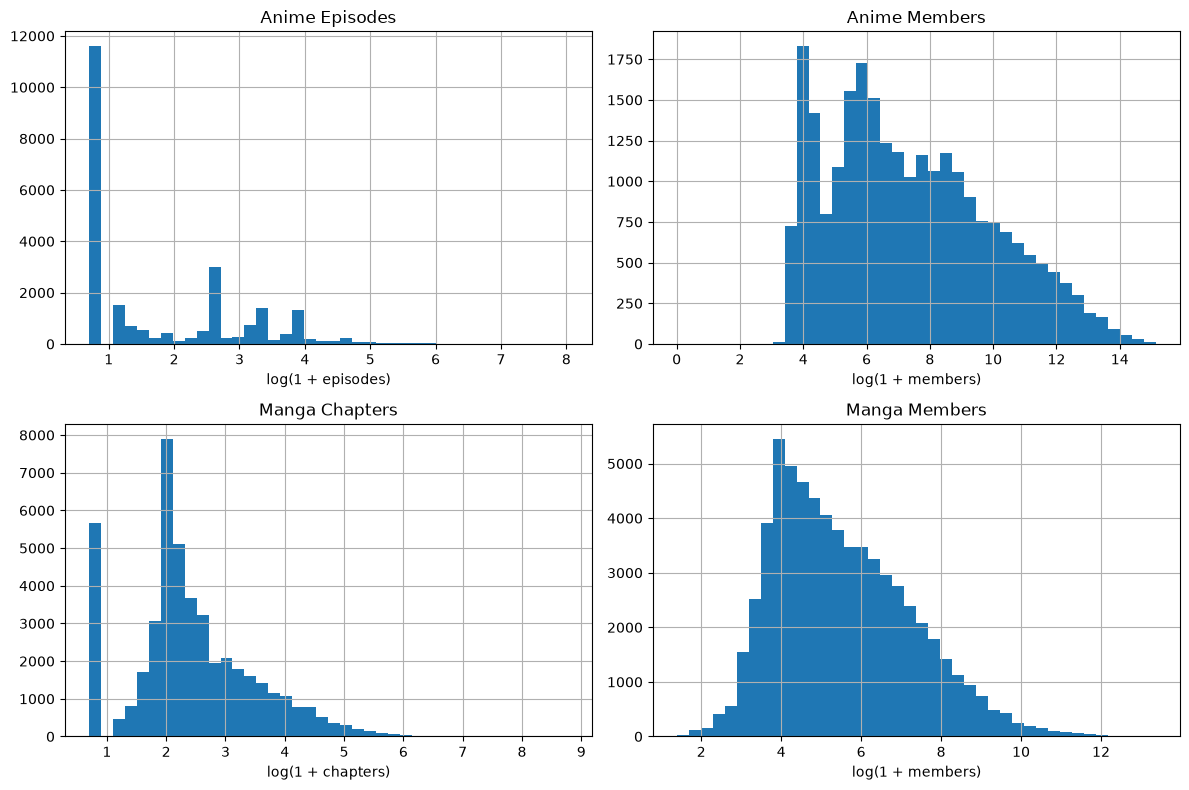

In [27]:
# Problem 6 - Histograms

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

anime_clean["episodes"].dropna().pipe(np.log1p).hist(
    bins=40, ax=axes[0, 0]
)
axes[0, 0].set_title("Anime Episodes")
axes[0, 0].set_xlabel("log(1 + episodes)")

anime_clean["members"].dropna().pipe(np.log1p).hist(
    bins=40, ax=axes[0, 1]
)
axes[0, 1].set_title("Anime Members")
axes[0, 1].set_xlabel("log(1 + members)")

manga_clean["chapters"].dropna().pipe(np.log1p).hist(
    bins=40, ax=axes[1, 0]
)
axes[1, 0].set_title("Manga Chapters")
axes[1, 0].set_xlabel("log(1 + chapters)")

manga_clean["members"].dropna().pipe(np.log1p).hist(
    bins=40, ax=axes[1, 1]
)
axes[1, 1].set_title("Manga Members")
axes[1, 1].set_xlabel("log(1 + members)")

plt.tight_layout()
plt.show()

In [28]:
# Inspect duration formats

print("Episode duration examples:")
print(
    anime_clean["episode_duration"]
    .dropna()
    .value_counts()
    .head(20)
)

print("\nTotal duration examples:")
print(
    anime_clean["total_duration"]
    .dropna()
    .value_counts()
    .head(20)
)

Episode duration examples:
episode_duration
0 days 00:24:00    1177
0 days 00:25:00     853
0 days 00:05:00     519
0 days 00:23:40     442
0 days 00:30:00     432
0 days 00:23:00     413
0 days 00:03:00     372
0 days 00:15:00     298
0 days 00:10:00     275
0 days 00:02:00     275
0 days 00:04:00     260
0 days 00:12:20     254
0 days 00:24:20     246
0 days 00:13:20     230
0 days 00:12:00     216
0 days 00:01:00     216
0 days 00:20:00     198
0 days 00:00:30     198
0 days 00:02:25     189
0 days 00:13:00     174
Name: count, dtype: int64

Total duration examples:
total_duration
0 days 04:48:00    345
0 days 00:30:00    271
0 days 04:44:00    248
0 days 01:30:00    229
0 days 00:24:00    228
0 days 01:00:00    226
0 days 05:12:00    214
0 days 00:02:25    186
0 days 00:25:00    173
0 days 00:15:00    160
0 days 00:10:00    159
0 days 00:48:00    146
0 days 00:20:00    142
0 days 10:50:00    139
0 days 00:04:00    136
0 days 10:24:00    129
0 days 00:50:00    126
0 days 00:03:00   

In [29]:
# Convert durations to minutes

anime_clean["episode_duration_minutes"] = (
    pd.to_timedelta(
        anime_clean["episode_duration"],
        errors="coerce"
    ).dt.total_seconds() / 60
)

anime_clean["total_duration_minutes"] = (
    pd.to_timedelta(
        anime_clean["total_duration"],
        errors="coerce"
    ).dt.total_seconds() / 60
)

display(
    anime_clean[
        [
            "episode_duration_minutes",
            "total_duration_minutes"
        ]
    ].describe().T
)

,count,mean,std,min,25%,50%,75%,max
episode_duration_minutes,24387.0,22.248507,24.399152,0.05,4.8,17.0,25.0,168.016667
total_duration_minutes,24162.0,227.700690,627.349934,0.05,11.0,55.0,284.0,36775.000000


In [30]:
duration_cols = [
    "episode_duration_minutes",
    "total_duration_minutes"
]

print("Missing values:")
print(anime_clean[duration_cols].isna().sum())

print("\nZero durations:")
print(anime_clean[duration_cols].eq(0).sum())

print("\nNegative durations:")
print(anime_clean[duration_cols].lt(0).sum())

Missing values:
episode_duration_minutes    598
total_duration_minutes      823
dtype: int64

Zero durations:
episode_duration_minutes    0
total_duration_minutes      0
dtype: int64

Negative durations:
episode_duration_minutes    0
total_duration_minutes      0
dtype: int64


In [31]:
# Check extreme durations

display(
    anime_clean[
        [
            "title",
            "episodes",
            "episode_duration_minutes",
            "total_duration_minutes"
        ]
    ].sort_values(
        by="total_duration_minutes",
        ascending=False
    ).head(10)
)

,title,episodes,episode_duration_minutes,total_duration_minutes
10492,Manga Nippon Mukashibanashi (1976),1471.0,25.000000,36775.000000
12489,Lan Mao,3057.0,11.500000,35155.500000
1120,Doraemon (1979),1787.0,11.000000,19657.000000
11663,Shima Shima Tora no Shimajirou,726.0,23.500000,17061.000000
22206,Tianyan Guilai,624.0,22.333333,13936.000000
59,Naruto: Shippuuden,500.0,23.150000,11575.000000
22727,Daomei Xiansheng,1664.0,6.333333,10538.666667
22272,Qi Qu Baodian Julebu,499.0,20.333333,10146.333333
2483,Kochira Katsushikaku Kameari Kouenmae Hashutsujo,373.0,25.000000,9325.000000
22445,Luo Baobei Ting Gushi,365.0,25.333333,9246.666667


### Problem 6 — Counters and Summary Statistics

#### Data Cleaning
- Numerical columns were checked for missing, zero, and negative values.
- No negative counts were found.
- Missing values were preserved as `NaN`.
- Zero values in `favorites` and `scored_by` were considered potentially valid.
- Anime episode and total durations were converted into minutes.

#### Summary Statistics
- Anime episodes: mean = 14.88, median = 2.
- Manga chapters: mean = 21.19, median = 9.
- Anime members: mean = 37,584, median = 1,085.
- Average anime episode duration = 22.25 minutes.
- Median anime episode duration = 17 minutes.
- Average total anime duration = 227.70 minutes.

#### Distribution Analysis
- Histograms revealed strongly right-skewed distributions.
- Logarithmic transformations improved the visualization of skewed numerical variables.
- A small number of popular or long-running series have extremely high values.
- Extreme total durations were consistent with episode counts and episode lengths in the inspected examples.

#### Conclusion
The numerical distributions are strongly right-skewed, making the median an important complement to the mean. Missing values and extreme observations were preserved unless there was sufficient evidence of an error.

### Problem 7. Lists, part 1: descriptions
Many of the columns are not tidy at all. They contain an entire list within a cell. What can you do about them?

Start by providing descriptive statistics about such columns. How long are these lists? How many of them only have one element; e.g., for genres - how useful would it be to only consider one genre per anime / manga? How useful are manga demongraphics and how often do they appear in sets of many? Try exploring the data and maybe applying some domain knowledge. Don't forget to analyze empty lists.

In [32]:
# Problem 7 - Lists, Part 1: Descriptions

anime_list_cols = [
    "genres",
    "themes",
    "demographics",
    "studios",
    "producers",
    "licensors"
]

manga_list_cols = [
    "genres",
    "themes",
    "demographics",
    "authors",
    "serializations"
]

print("ANIME LIST EXAMPLES")
display(anime_clean[anime_list_cols].head(5))

print("\nMANGA LIST EXAMPLES")
display(manga_clean[manga_list_cols].head(5))


ANIME LIST EXAMPLES


,genres,themes,demographics,studios,producers,licensors
0,"['Action', 'Adventure', 'Drama', 'Fantasy']",['Military'],['Shounen'],['Bones'],"['Aniplex', 'Square Enix', 'Mainichi Broadcast...","['Funimation', 'Aniplex of America']"
1,"['Action', 'Adventure', 'Fantasy']",[],['Shounen'],['Madhouse'],"['VAP', 'Nippon Television Network', 'Shueisha']",['VIZ Media']
2,"['Action', 'Drama']","['Gore', 'Military', 'Survival']",['Shounen'],['Wit Studio'],"['Production I.G', 'Dentsu', 'Mainichi Broadca...",['Funimation']
3,"['Drama', 'Sci-Fi', 'Suspense']","['Psychological', 'Time Travel']",[],['White Fox'],"['Frontier Works', 'Media Factory', 'Kadokawa ...",['Funimation']
4,"['Award Winning', 'Drama']",['Romantic Subtext'],['Shounen'],['Kyoto Animation'],"['Shochiku', 'Pony Canyon', 'Kodansha', 'ABC A...","['Eleven Arts', 'NYAV Post']"



MANGA LIST EXAMPLES


,genres,themes,demographics,authors,serializations
0,"['Action', 'Adventure', 'Award Winning', 'Dram...","['Gore', 'Military', 'Mythology', 'Psychologic...",['Seinen'],"[{'id': 1868, 'first_name': 'Kentarou', 'last_...",['Young Animal']
1,"['Action', 'Adventure', 'Fantasy']",[],['Shounen'],"[{'id': 1881, 'first_name': 'Eiichiro', 'last_...",['Shounen Jump (Weekly)']
2,"['Action', 'Adventure', 'Mystery', 'Supernatur...",['Historical'],"['Seinen', 'Shounen']","[{'id': 2619, 'first_name': 'Hirohiko', 'last_...",['Ultra Jump']
3,"['Drama', 'Slice of Life']",['Psychological'],['Seinen'],"[{'id': 2836, 'first_name': 'Inio', 'last_name...",['Big Comic Spirits']
4,"['Action', 'Adventure', 'Award Winning', 'Dram...",['Military'],['Shounen'],"[{'id': 1874, 'first_name': 'Hiromu', 'last_na...",['Shounen Gangan']


In [33]:
import ast

def parse_list(value):
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    try:
        result = ast.literal_eval(value)
        return result if isinstance(result, list) else []
    except (ValueError, SyntaxError, TypeError):
        return []

In [34]:
# Parse list columns

for col in anime_list_cols:
    anime_clean[col + "_list"] = (
        anime_clean[col].apply(parse_list)
    )

for col in manga_list_cols:
    manga_clean[col + "_list"] = (
        manga_clean[col].apply(parse_list)
    )

In [35]:
# Calculate list lengths

for col in anime_list_cols:
    anime_clean[col + "_count"] = (
        anime_clean[col + "_list"].apply(len)
    )

for col in manga_list_cols:
    manga_clean[col + "_count"] = (
        manga_clean[col + "_list"].apply(len)
    )

In [36]:
def list_statistics(df, columns):
    results = []

    for col in columns:
        counts = df[col + "_count"]

        results.append({
            "column": col,
            "mean_length": round(counts.mean(), 2),
            "median_length": counts.median(),
            "max_length": counts.max(),
            "empty_lists": (counts == 0).sum(),
            "single_element": (counts == 1).sum(),
            "multiple_elements": (counts > 1).sum()
        })

    return pd.DataFrame(results).set_index("column")


print("ANIME LIST STATISTICS")
display(list_statistics(anime_clean, anime_list_cols))

print("\nMANGA LIST STATISTICS")
display(list_statistics(manga_clean, manga_list_cols))

ANIME LIST STATISTICS


,mean_length,median_length,max_length,empty_lists,single_element,multiple_elements
column,,,,,,
genres,1.54,1.0,10,4988,8872,11125
themes,0.78,1.0,6,11020,9649,4316
demographics,0.38,0.0,2,15471,9437,77
studios,0.63,1.0,10,10418,13529,1038
producers,1.01,0.0,20,13301,6722,4962
licensors,0.23,0.0,5,20234,3928,823



MANGA LIST STATISTICS


,mean_length,median_length,max_length,empty_lists,single_element,multiple_elements
column,,,,,,
genres,1.87,2.0,9,2412,24956,37465
themes,0.48,0.0,5,40536,18663,5634
demographics,0.41,0.0,2,38491,26297,45
authors,1.41,1.0,86,550,44509,19774
serializations,0.67,1.0,1,21389,43444,0


In [37]:
# Most common genres

anime_genres = (
    anime_clean["genres_list"]
    .explode()
    .dropna()
    .value_counts()
)

manga_genres = (
    manga_clean["genres_list"]
    .explode()
    .dropna()
    .value_counts()
)

print("TOP 10 ANIME GENRES")
display(anime_genres.head(10))

print("\nTOP 10 MANGA GENRES")
display(manga_genres.head(10))

TOP 10 ANIME GENRES


genres_list
Comedy           7154
Fantasy          5326
Action           4744
Adventure        3841
Sci-Fi           3108
Drama            2839
Romance          2065
Slice of Life    1701
Supernatural     1489
Hentai           1486
Name: count, dtype: int64


TOP 10 MANGA GENRES


genres_list
Romance          16876
Comedy           14099
Hentai           11208
Fantasy          10952
Boys Love         9610
Drama             9303
Action            8910
Erotica           8844
Supernatural      7471
Slice of Life     5155
Name: count, dtype: int64

In [38]:
# Manga demographics distribution

manga_demographics = (
    manga_clean["demographics_list"]
    .explode()
    .dropna()
    .value_counts()
)

print("MANGA DEMOGRAPHICS")
display(manga_demographics)

print("\nPercent of all manga:")
display(
    (manga_demographics / len(manga_clean) * 100).round(2)
)

MANGA DEMOGRAPHICS


demographics_list
Shoujo     8188
Seinen     7680
Shounen    6297
Josei      3960
Kids        262
Name: count, dtype: int64


Percent of all manga:


demographics_list
Shoujo     12.63
Seinen     11.85
Shounen     9.71
Josei       6.11
Kids        0.40
Name: count, dtype: float64

### Problem 7 — Lists, Part 1: Descriptions

#### Data Structure
- Several columns contain lists stored as strings.
- These columns were converted into Python lists using `ast.literal_eval()`.
- List lengths were calculated for each column.
- Empty lists, single-element lists, and multiple-element lists were analyzed.

#### Genre Analysis
- Anime: 44.5% of titles have multiple genres.
- Manga: 57.8% of titles have multiple genres.
- Anime: 4,988 titles have empty genre lists.
- Manga: 2,412 titles have empty genre lists.
- The most common anime genre is Comedy (7,154 titles).
- The most common manga genre is Romance (16,876 titles).
- Considering only one genre per title would result in substantial information loss.

#### Manga Demographics
- 38,491 manga titles (59.37%) have no demographic classification.
- 26,297 titles have exactly one demographic category.
- Only 45 titles (0.07%) have multiple demographic categories.
- The most common categories are:
  - Shoujo: 8,188 (12.63%)
  - Seinen: 7,680 (11.85%)
  - Shounen: 6,297 (9.71%)
  - Josei: 3,960 (6.11%)
  - Kids: 262 (0.40%)

#### Other List Columns
- Anime themes and licensors contain many empty lists.
- Manga themes are empty for approximately 62.5% of titles.
- Manga authors have an average list length of 1.41.
- Manga serializations contain at most one element per title.

#### Conclusion
Genres should be treated as multi-label categorical data because many titles belong to multiple genres.

Manga demographics usually contain a single category when available, but the high proportion of empty lists limits their usefulness.

Preserving the complete lists is preferable to selecting only the first element.

### * Problem 8. Lists, part 2: cleaning
Try to extract the lists into separate entities (datasets). You'll need to look up "one to many" and "many to many" relationships. Start by using `.split()` and the `explode` parameter. Document your process, findings, and results. It would be useful to extract some utility functions if you find that you keep repeating code.

It's a good idea to save your cleaned / processed (somewhat) / extracted dataset(s) now.

In [39]:
# Problem 8 - Extract Anime Genres

anime_genres_df = (
    anime_clean[["anime_id", "genres_list"]]
    .explode("genres_list")
    .rename(columns={"genres_list": "genre"})
    .dropna(subset=["genre"])
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Anime Genres dataset:")
print(anime_genres_df.shape)

display(anime_genres_df.head(15))

Anime Genres dataset:
(38474, 2)


,anime_id,genre
0,5114,Action
1,5114,Adventure
2,5114,Drama
3,5114,Fantasy
4,11061,Action
5,11061,Adventure
6,11061,Fantasy
7,38524,Action
8,38524,Drama
9,9253,Drama


In [40]:
# Extract Manga Genres

manga_genres_df = (
    manga_clean[["manga_id", "genres_list"]]
    .explode("genres_list")
    .rename(columns={"genres_list": "genre"})
    .dropna(subset=["genre"])
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Manga Genres dataset:")
print(manga_genres_df.shape)

display(manga_genres_df.head(15))

Manga Genres dataset:
(121442, 2)


,manga_id,genre
0,2,Action
1,2,Adventure
2,2,Award Winning
3,2,Drama
4,2,Fantasy
5,2,Horror
6,2,Supernatural
7,13,Action
8,13,Adventure
9,13,Fantasy


In [41]:
# Utility function for extracting list columns

def extract_list(df, id_col, list_col, new_col):
    result = (
        df[[id_col, list_col]]
        .explode(list_col)
        .rename(columns={list_col: new_col})
        .dropna(subset=[new_col])
        .drop_duplicates()
        .reset_index(drop=True)
    )

    return result

In [42]:
# Extract themes using the utility function

anime_themes_df = extract_list(
    anime_clean,
    "anime_id",
    "themes_list",
    "theme"
)

manga_themes_df = extract_list(
    manga_clean,
    "manga_id",
    "themes_list",
    "theme"
)

print("Anime Themes:", anime_themes_df.shape)
display(anime_themes_df.head(10))

print("\nManga Themes:", manga_themes_df.shape)
display(manga_themes_df.head(10))

Anime Themes: (19578, 2)


,anime_id,theme
0,5114,Military
1,38524,Gore
2,38524,Military
3,38524,Survival
4,9253,Psychological
5,9253,Time Travel
6,28851,Romantic Subtext
7,32281,Romantic Subtext
8,2904,Mecha
9,2904,Military



Manga Themes: (31005, 2)


,manga_id,theme
0,2,Gore
1,2,Military
2,2,Mythology
3,2,Psychological
4,1706,Historical
5,4632,Psychological
6,25,Military
7,656,Historical
8,656,Samurai
9,642,Historical


In [43]:
# Extract remaining list columns

anime_demographics_df = extract_list(
    anime_clean, "anime_id", "demographics_list", "demographic"
)

anime_studios_df = extract_list(
    anime_clean, "anime_id", "studios_list", "studio"
)

anime_producers_df = extract_list(
    anime_clean, "anime_id", "producers_list", "producer"
)

anime_licensors_df = extract_list(
    anime_clean, "anime_id", "licensors_list", "licensor"
)

manga_demographics_df = extract_list(
    manga_clean, "manga_id", "demographics_list", "demographic"
)

manga_serializations_df = extract_list(
    manga_clean, "manga_id", "serializations_list", "serialization"
)

# Summary of extracted datasets

extracted_datasets = {
    "anime_demographics": anime_demographics_df,
    "anime_studios": anime_studios_df,
    "anime_producers": anime_producers_df,
    "anime_licensors": anime_licensors_df,
    "manga_demographics": manga_demographics_df,
    "manga_serializations": manga_serializations_df
}

for name, df in extracted_datasets.items():
    print(f"{name}: {df.shape}")

anime_demographics: (9591, 2)
anime_studios: (15717, 2)
anime_producers: (25288, 2)
anime_licensors: (5645, 2)
manga_demographics: (26387, 2)
manga_serializations: (43444, 2)


In [44]:
# Extract Manga Authors

manga_authors_exploded = (
    manga_clean[["manga_id", "authors_list"]]
    .explode("authors_list")
    .dropna(subset=["authors_list"])
    .reset_index(drop=True)
)

# Inspect the structure of an author
print("Example author:")
print(manga_authors_exploded["authors_list"].iloc[0])

print("\nType:")
print(type(manga_authors_exploded["authors_list"].iloc[0]))

Example author:
{'id': 1868, 'first_name': 'Kentarou', 'last_name': 'Miura', 'role': 'Story & Art'}

Type:
<class 'dict'>


In [45]:
# Normalize Manga Authors

authors_data = pd.json_normalize(
    manga_authors_exploded["authors_list"]
)

manga_authors_df = pd.concat(
    [
        manga_authors_exploded[["manga_id"]].reset_index(drop=True),
        authors_data.reset_index(drop=True)
    ],
    axis=1
)

manga_authors_df = (
    manga_authors_df
    .rename(columns={"id": "author_id"})
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Manga Authors dataset:")
print(manga_authors_df.shape)

display(manga_authors_df.head(10))

Manga Authors dataset:
(91430, 5)


,manga_id,author_id,first_name,last_name,role
0,2,1868,Kentarou,Miura,Story & Art
1,2,49592,,Studio Gaga,Art
2,13,1881,Eiichiro,Oda,Story & Art
3,1706,2619,Hirohiko,Araki,Story & Art
4,4632,2836,Inio,Asano,Story & Art
5,25,1874,Hiromu,Arakawa,Story & Art
6,656,1911,Takehiko,Inoue,Story & Art
7,656,5760,Eiji,Yoshikawa,Story
8,642,2034,Makoto,Yukimura,Story & Art
9,90125,2139,Aka,Akasaka,Story & Art


In [46]:
# Create unique Authors dataset

authors_df = (
    manga_authors_df[
        ["author_id", "first_name", "last_name"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

# Create Manga-Authors relationship dataset

manga_authors_rel_df = (
    manga_authors_df[
        ["manga_id", "author_id", "role"]
    ]
    .drop_duplicates()
    .reset_index(drop=True)
)

print("Unique Authors:", authors_df.shape)
print("Manga-Authors Relationships:", manga_authors_rel_df.shape)

print("\nAuthors:")
display(authors_df.head(10))

print("\nRelationships:")
display(manga_authors_rel_df.head(10))

# Check author ID uniqueness
print(
    "\nDuplicate author IDs:",
    authors_df["author_id"].duplicated().sum()
)

Unique Authors: (26144, 3)
Manga-Authors Relationships: (91430, 3)

Authors:


,author_id,first_name,last_name
0,1868,Kentarou,Miura
1,49592,,Studio Gaga
2,1881,Eiichiro,Oda
3,2619,Hirohiko,Araki
4,2836,Inio,Asano
5,1874,Hiromu,Arakawa
6,1911,Takehiko,Inoue
7,5760,Eiji,Yoshikawa
8,2034,Makoto,Yukimura
9,2139,Aka,Akasaka



Relationships:


,manga_id,author_id,role
0,2,1868,Story & Art
1,2,49592,Art
2,13,1881,Story & Art
3,1706,2619,Story & Art
4,4632,2836,Story & Art
5,25,1874,Story & Art
6,656,1911,Story & Art
7,656,5760,Story
8,642,2034,Story & Art
9,90125,2139,Story & Art



Duplicate author IDs: 0


In [47]:
# Problem 8 - Data Integrity Checks

missing_authors = (
    ~manga_authors_rel_df["author_id"]
    .isin(authors_df["author_id"])
).sum()

missing_manga = (
    ~manga_authors_rel_df["manga_id"]
    .isin(manga_clean["manga_id"])
).sum()

duplicate_relations = manga_authors_rel_df.duplicated(
    subset=["manga_id", "author_id", "role"]
).sum()

print("Missing author references:", missing_authors)
print("Missing manga references:", missing_manga)
print("Duplicate relationships:", duplicate_relations)

Missing author references: 0
Missing manga references: 0
Duplicate relationships: 0


In [48]:
from pathlib import Path

# Create output directory
output_dir = Path("processed_data")
output_dir.mkdir(exist_ok=True)

# All extracted datasets
datasets = {
    "anime_clean": anime_clean,
    "manga_clean": manga_clean,
    "anime_genres": anime_genres_df,
    "manga_genres": manga_genres_df,
    "anime_themes": anime_themes_df,
    "manga_themes": manga_themes_df,
    "anime_demographics": anime_demographics_df,
    "manga_demographics": manga_demographics_df,
    "anime_studios": anime_studios_df,
    "anime_producers": anime_producers_df,
    "anime_licensors": anime_licensors_df,
    "manga_serializations": manga_serializations_df,
    "authors": authors_df,
    "manga_authors_rel": manga_authors_rel_df
}

# Save as CSV
for name, df in datasets.items():
    file_path = output_dir / f"{name}.csv"
    df.to_csv(file_path, index=False)
    print(f"Saved: {file_path} | Shape: {df.shape}")

Saved: processed_data\anime_clean.csv | Shape: (24985, 58)
Saved: processed_data\manga_clean.csv | Shape: (64833, 45)
Saved: processed_data\anime_genres.csv | Shape: (38474, 2)
Saved: processed_data\manga_genres.csv | Shape: (121442, 2)
Saved: processed_data\anime_themes.csv | Shape: (19578, 2)
Saved: processed_data\manga_themes.csv | Shape: (31005, 2)
Saved: processed_data\anime_demographics.csv | Shape: (9591, 2)
Saved: processed_data\manga_demographics.csv | Shape: (26387, 2)
Saved: processed_data\anime_studios.csv | Shape: (15717, 2)
Saved: processed_data\anime_producers.csv | Shape: (25288, 2)
Saved: processed_data\anime_licensors.csv | Shape: (5645, 2)
Saved: processed_data\manga_serializations.csv | Shape: (43444, 2)
Saved: processed_data\authors.csv | Shape: (26144, 3)
Saved: processed_data\manga_authors_rel.csv | Shape: (91430, 3)


### Problem 8 — Lists, Part 2: Cleaning

#### Data Extraction

List-based columns were converted into separate relational datasets using Pandas `explode()`.

A reusable utility function, `extract_list()`, was created to avoid code duplication.

The extracted datasets include:
- Anime and Manga genres
- Anime and Manga themes
- Anime and Manga demographics
- Anime studios, producers, and licensors
- Manga serializations
- Manga authors and their roles

#### Relational Structure

Most extracted categories represent many-to-many relationships.

For example, one anime can have multiple genres, while one genre can belong to multiple anime titles.

Manga authors required additional processing because the original lists contained dictionaries.

The dictionaries were normalized using `pd.json_normalize()`.

Two separate datasets were created:
- `authors_df`: 26,144 unique authors
- `manga_authors_rel_df`: 91,430 relationships between manga and authors

#### Data Integrity

The following checks were performed:

- Missing author references: 0
- Missing manga references: 0
- Duplicate author IDs: 0
- Duplicate manga-author-role relationships: 0

These results confirm the consistency of the extracted manga-author relationships.

#### Saving Processed Data

A total of 14 CSV files were saved in the `processed_data` directory.

The files include two cleaned main datasets and twelve extracted relational datasets.

The original records were preserved, including titles with empty lists. Such titles simply have no corresponding rows in the extracted relationship tables.

#### Conclusion

The list-based columns were successfully transformed into structured relational datasets.

Using `explode()` and reusable utility functions made the extraction process consistent and efficient.

Separating authors from manga-author relationships reduced data redundancy and improved the relational structure.

The processed datasets are now ready for further analysis and exploration.

### Problem 9. Interesting cases
Find some extreme cases, unusual cases, and especially interesting rows. At least one of your questions should force you to think about what "top" or "best" actually means, rather than blindly sorting by one column.

I love these kinds of problems, because they appear often in real life, and we usually don't know how to approach them. Think, for example, about "duration" - do we want to find longest-running animes? Do we mean runtime, or earliest start date? How do we take into account new (and still not completed) series vs. older ones? Or, as a different example - how do we measure popularity? Do we average by time? Do we take into account any recency bias?

In [49]:
# Problem 9 - Longest Anime

# Top 10 by number of episodes
top_episodes = (
    anime_clean[
        ["title", "episodes", "total_duration_minutes", "status"]
    ]
    .sort_values("episodes", ascending=False)
    .head(10)
)

print("TOP 10 ANIME BY EPISODES")
display(top_episodes)

# Top 10 by total runtime
top_runtime = (
    anime_clean[
        ["title", "episodes", "total_duration_minutes", "status"]
    ]
    .sort_values("total_duration_minutes", ascending=False)
    .head(10)
)

print("\nTOP 10 ANIME BY TOTAL RUNTIME")
display(top_runtime)

TOP 10 ANIME BY EPISODES


,title,episodes,total_duration_minutes,status
12489,Lan Mao,3057.0,35155.500000,finished_airing
12920,Oyako Club,1818.0,9090.000000,finished_airing
1120,Doraemon (1979),1787.0,19657.000000,finished_airing
22727,Daomei Xiansheng,1664.0,10538.666667,finished_airing
13555,Kirin Monoshiri Yakata,1565.0,7825.000000,finished_airing
10492,Manga Nippon Mukashibanashi (1976),1471.0,36775.000000,finished_airing
12655,Hokahoka Kazoku,1428.0,7140.000000,finished_airing
13438,Kirin Ashita no Calendar,1306.0,6530.000000,finished_airing
13950,Monoshiri Daigaku: Ashita no Calendar,1274.0,6370.000000,finished_airing
13712,Sekai Monoshiri Ryoko,1006.0,5030.000000,finished_airing



TOP 10 ANIME BY TOTAL RUNTIME


,title,episodes,total_duration_minutes,status
10492,Manga Nippon Mukashibanashi (1976),1471.0,36775.000000,finished_airing
12489,Lan Mao,3057.0,35155.500000,finished_airing
1120,Doraemon (1979),1787.0,19657.000000,finished_airing
11663,Shima Shima Tora no Shimajirou,726.0,17061.000000,finished_airing
22206,Tianyan Guilai,624.0,13936.000000,finished_airing
59,Naruto: Shippuuden,500.0,11575.000000,finished_airing
22727,Daomei Xiansheng,1664.0,10538.666667,finished_airing
22272,Qi Qu Baodian Julebu,499.0,10146.333333,finished_airing
2483,Kochira Katsushikaku Kameari Kouenmae Hashutsujo,373.0,9325.000000,finished_airing
22445,Luo Baobei Ting Gushi,365.0,9246.666667,finished_airing


In [50]:
# Problem 9 - Longest Anime by Calendar Duration

completed_anime = anime_clean[
    (anime_clean["status"] == "finished_airing")
    & (anime_clean["real_start_date_precision"] == "day")
    & (anime_clean["real_end_date_precision"] == "day")
    & anime_clean["real_start_date"].notna()
    & anime_clean["real_end_date"].notna()
].copy()

completed_anime["duration_years"] = (
    (
        completed_anime["real_end_date"]
        - completed_anime["real_start_date"]
    ).dt.days / 365.25
)

# Exclude inconsistent negative durations
completed_anime = completed_anime[
    completed_anime["duration_years"] >= 0
]

top_calendar = (
    completed_anime[
        [
            "title",
            "real_start_date",
            "real_end_date",
            "duration_years",
            "episodes"
        ]
    ]
    .sort_values("duration_years", ascending=False)
    .head(10)
)

print("TOP 10 ANIME BY CALENDAR DURATION")
display(top_calendar)

TOP 10 ANIME BY CALENDAR DURATION


,title,real_start_date,real_end_date,duration_years,episodes
1120,Doraemon (1979),1979-04-02,2005-03-18,25.960301,1787.0
15507,Kirin no Otenki Mama-san,1964-06-26,1984-10-06,20.279261,12.0
10492,Manga Nippon Mukashibanashi (1976),1976-01-07,1994-09-03,18.655715,1471.0
12920,Oyako Club,1994-10-03,2013-03-30,18.488706,1818.0
2045,Black Jack,1993-12-21,2011-12-16,17.984942,12.0
11663,Shima Shima Tora no Shimajirou,1993-12-13,2008-03-31,14.297057,726.0
19646,Aresuke,2008-01-01,2020-10-06,12.763860,13.0
6336,Shounan Bakusouzoku,1986-09-10,1999-03-12,12.501027,12.0
14707,Worku,2005-04-05,2017-03-14,11.939767,2.0
4564,Gensou Mangekyou: The Memories of Phantasm,2011-08-12,2023-05-07,11.734428,18.0


In [51]:
# Problem 9 - Best Anime

# Highest scores without a minimum vote count
top_score = (
    anime_clean[
        ["title", "score", "scored_by", "members"]
    ]
    .dropna(subset=["score", "scored_by"])
    .sort_values("score", ascending=False)
    .head(10)
)

print("TOP 10 ANIME BY SCORE")
display(top_score)

# Highest scores with at least 10,000 ratings
top_score_reliable = (
    anime_clean[
        ["title", "score", "scored_by", "members"]
    ]
    .dropna(subset=["score", "scored_by"])
    .query("scored_by >= 10000")
    .sort_values("score", ascending=False)
    .head(10)
)

print("\nTOP 10 ANIME BY SCORE (MINIMUM 10,000 RATINGS)")
display(top_score_reliable)

TOP 10 ANIME BY SCORE


,title,score,scored_by,members
0,Fullmetal Alchemist: Brotherhood,9.10,2037075,3206028
3,Steins;Gate,9.07,1348232,2463954
103,Gintama°,9.06,240466,602466
114,Bleach: Sennen Kessen-hen,9.06,228906,465617
2,Shingeki no Kyojin Season 3 Part 2,9.05,1491491,2133927
1,Hunter x Hunter (2011),9.04,1671587,2688079
117,Gintama',9.04,228236,531630
477,Gintama: The Final,9.04,65116,135944
187,Shingeki no Kyojin: The Final Season - Kankets...,9.04,170844,462550
38,Kaguya-sama wa Kokurasetai: Ultra Romantic,9.04,466692,843192



TOP 10 ANIME BY SCORE (MINIMUM 10,000 RATINGS)


,title,score,scored_by,members
0,Fullmetal Alchemist: Brotherhood,9.10,2037075,3206028
3,Steins;Gate,9.07,1348232,2463954
103,Gintama°,9.06,240466,602466
114,Bleach: Sennen Kessen-hen,9.06,228906,465617
2,Shingeki no Kyojin Season 3 Part 2,9.05,1491491,2133927
38,Kaguya-sama wa Kokurasetai: Ultra Romantic,9.04,466692,843192
187,Shingeki no Kyojin: The Final Season - Kankets...,9.04,170844,462550
1,Hunter x Hunter (2011),9.04,1671587,2688079
477,Gintama: The Final,9.04,65116,135944
117,Gintama',9.04,228236,531630


In [52]:
# Problem 9 - Weighted Rating

anime_rated = anime_clean[
    ["title", "score", "scored_by", "members"]
].dropna(subset=["score", "scored_by"]).copy()

anime_rated = anime_rated[
    anime_rated["scored_by"] > 0
]

C = anime_rated["score"].mean()
m = anime_rated["scored_by"].quantile(0.90)

anime_rated["weighted_rating"] = (
    (anime_rated["scored_by"] /
     (anime_rated["scored_by"] + m))
    * anime_rated["score"]
    +
    (m / (anime_rated["scored_by"] + m))
    * C
)

print(f"Global mean score (C): {C:.4f}")
print(f"90th percentile of ratings count (m): {m:.0f}")

print("\nTOP 10 ANIME BY WEIGHTED RATING")

display(
    anime_rated.sort_values(
        "weighted_rating", ascending=False
    )[
        ["title", "score", "scored_by", "weighted_rating"]
    ].head(10)
)

Global mean score (C): 6.4185
90th percentile of ratings count (m): 59017

TOP 10 ANIME BY WEIGHTED RATING


,title,score,scored_by,weighted_rating
0,Fullmetal Alchemist: Brotherhood,9.10,2037075,9.024500
3,Steins;Gate,9.07,1348232,8.958801
1,Hunter x Hunter (2011),9.04,1671587,8.950601
2,Shingeki no Kyojin Season 3 Part 2,9.05,1491491,8.949836
4,Koe no Katachi,8.94,1540277,8.846951
6,Code Geass: Hangyaku no Lelouch R2,8.91,1154270,8.788807
5,Kimi no Na wa.,8.84,1825476,8.764165
38,Kaguya-sama wa Kokurasetai: Ultra Romantic,9.04,466692,8.745703
27,Clannad: After Story,8.93,643382,8.718977
7,Shingeki no Kyojin: The Final Season,8.80,1237778,8.691617


In [53]:
# Problem 9 - Anime Popularity

top_members = (
    anime_clean[
        ["title", "members", "favorites", "score"]
    ]
    .sort_values("members", ascending=False)
    .head(10)
)

top_favorites = (
    anime_clean[
        ["title", "members", "favorites", "score"]
    ]
    .sort_values("favorites", ascending=False)
    .head(10)
)

print("TOP 10 ANIME BY MEMBERS")
display(top_members)

print("\nTOP 10 ANIME BY FAVORITES")
display(top_favorites)

TOP 10 ANIME BY MEMBERS


,title,members,favorites,score
16,Shingeki no Kyojin,3779820,165109,8.54
10,Death Note,3747523,168772,8.62
0,Fullmetal Alchemist: Brotherhood,3206028,219036,9.10
20,One Punch Man,3087808,62773,8.50
1206,Sword Art Online,2973952,67354,7.20
225,Boku no Hero Academia,2908788,53438,7.89
24,Kimetsu no Yaiba,2853413,89446,8.50
173,Naruto,2742992,76996,7.99
294,Tokyo Ghoul,2721331,49358,7.79
1,Hunter x Hunter (2011),2688079,202109,9.04



TOP 10 ANIME BY FAVORITES


,title,members,favorites,score
0,Fullmetal Alchemist: Brotherhood,3206028,219036,9.10
11,One Piece,2204897,203640,8.70
1,Hunter x Hunter (2011),2688079,202109,9.04
3,Steins;Gate,2463954,184312,9.07
10,Death Note,3747523,168772,8.62
16,Shingeki no Kyojin,3779820,165109,8.54
59,Naruto: Shippuuden,2374806,108754,8.26
9,Code Geass: Hangyaku no Lelouch,2169252,106054,8.70
49,Neon Genesis Evangelion,1736961,101669,8.35
24,Kimetsu no Yaiba,2853413,89446,8.50


In [54]:
# Problem 9 - Favorites Ratio

anime_popularity = anime_clean[
    ["title", "members", "favorites", "score"]
].copy()

# Avoid division by zero
anime_popularity = anime_popularity[
    anime_popularity["members"] > 0
]

anime_popularity["favorites_ratio"] = (
    anime_popularity["favorites"]
    / anime_popularity["members"] * 100
)

# At least 10,000 members
top_ratio_10k = (
    anime_popularity[
        anime_popularity["members"] >= 10000
    ]
    .sort_values("favorites_ratio", ascending=False)
    .head(10)
)

# At least 100,000 members
top_ratio_100k = (
    anime_popularity[
        anime_popularity["members"] >= 100000
    ]
    .sort_values("favorites_ratio", ascending=False)
    .head(10)
)

print("TOP 10 FAVORITES RATIO - MIN 10,000 MEMBERS")
display(top_ratio_10k)

print("\nTOP 10 FAVORITES RATIO - MIN 100,000 MEMBERS")
display(top_ratio_100k)

TOP 10 FAVORITES RATIO - MIN 10,000 MEMBERS


,title,members,favorites,score,favorites_ratio
11,One Piece,2204897,203640,8.70,9.235806
1,Hunter x Hunter (2011),2688079,202109,9.04,7.518715
3,Steins;Gate,2463954,184312,9.07,7.480334
0,Fullmetal Alchemist: Brotherhood,3206028,219036,9.10,6.832005
27,Clannad: After Story,1157642,69183,8.93,5.976200
49,Neon Genesis Evangelion,1736961,101669,8.35,5.853269
53,Gintama,1031044,57986,8.94,5.624008
419,Ginga Eiyuu Densetsu,307951,15766,9.02,5.119646
1140,Ashita no Joe 2,48414,2454,8.71,5.068782
29,Tengen Toppa Gurren Lagann,1558970,76345,8.63,4.897144



TOP 10 FAVORITES RATIO - MIN 100,000 MEMBERS


,title,members,favorites,score,favorites_ratio
11,One Piece,2204897,203640,8.70,9.235806
1,Hunter x Hunter (2011),2688079,202109,9.04,7.518715
3,Steins;Gate,2463954,184312,9.07,7.480334
0,Fullmetal Alchemist: Brotherhood,3206028,219036,9.10,6.832005
27,Clannad: After Story,1157642,69183,8.93,5.976200
49,Neon Genesis Evangelion,1736961,101669,8.35,5.853269
53,Gintama,1031044,57986,8.94,5.624008
419,Ginga Eiyuu Densetsu,307951,15766,9.02,5.119646
29,Tengen Toppa Gurren Lagann,1558970,76345,8.63,4.897144
9,Code Geass: Hangyaku no Lelouch,2169252,106054,8.70,4.888966


In [55]:
# Problem 9 - Unusual Cases: High Scores, Few Ratings

unusual_scores = (
    anime_clean[
        ["title", "score", "scored_by", "members"]
    ]
    .dropna(subset=["score", "scored_by"])
    .query("scored_by > 0 and scored_by < 1000")
    .sort_values(
        ["score", "scored_by"],
        ascending=[False, False]
    )
    .head(10)
)

print("HIGH-SCORING ANIME WITH FEWER THAN 1,000 RATINGS")
display(unusual_scores)

print(
    "\nNumber of anime with fewer than 1,000 ratings:",
    len(
        anime_clean[
            (anime_clean["scored_by"] > 0)
            & (anime_clean["scored_by"] < 1000)
        ]
    )
)

HIGH-SCORING ANIME WITH FEWER THAN 1,000 RATINGS


,title,score,scored_by,members
5030,Shen Yin Wangzuo 2nd Season,7.90,814,2420
5417,Seishun Buta Yarou wa Odekake Sister no Yume w...,7.71,731,79742
5811,Kaibutsu,7.61,619,985
6745,Blue Giant,7.59,322,11425
5462,Sasaki to Miyano Movie: Sotsugyou-hen,7.58,797,29191
5652,Modern Love Tokyo: Kare ga Kanaderu Futari no ...,7.55,741,2527
5335,Yoku,7.54,908,1600
5437,Xingchen Bian: Po Tian Mi Ju,7.54,860,1980
5691,Kiratto Pri☆chan Season 2,7.53,741,2784
5767,Ganbare Genki,7.53,708,2754



Number of anime with fewer than 1,000 ratings: 15313


In [56]:
# Problem 9 - Unusual Manga Cases

top_chapters = (
    manga_clean[
        ["title", "chapters", "volumes", "status", "score"]
    ]
    .sort_values("chapters", ascending=False)
    .head(10)
)

top_volumes = (
    manga_clean[
        ["title", "chapters", "volumes", "status", "score"]
    ]
    .sort_values("volumes", ascending=False)
    .head(10)
)

print("TOP 10 MANGA BY CHAPTERS")
display(top_chapters)

print("\nTOP 10 MANGA BY VOLUMES")
display(top_volumes)

TOP 10 MANGA BY CHAPTERS


,title,chapters,volumes,status,score
19758,Sazae-san,6477.0,45.0,finished,6.75
5060,Kochira Katsushikaku Kameari Kouenmae Hashutsujo,1957.0,200.0,finished,7.56
12583,Asari-chan,1738.0,100.0,finished,7.22
27126,Denma,1410.0,19.0,finished,NaN
60733,3-Second Strip,1333.0,NaN,finished,NaN
35781,Nijitte Monogatari,1254.0,110.0,finished,NaN
42111,The Sound of Your Heart,1233.0,NaN,finished,NaN
26159,Shizukanaru Don: Yakuza Side Story,1175.0,108.0,finished,NaN
1255,Crayon Shin-chan,1126.0,50.0,finished,7.95
7586,Oishinbo,1039.0,111.0,on_hiatus,7.32



TOP 10 MANGA BY VOLUMES


,title,chapters,volumes,status,score
5060,Kochira Katsushikaku Kameari Kouenmae Hashutsujo,1957.0,200.0,finished,7.56
33270,Tantei Book: Kage,NaN,119.0,finished,NaN
27134,Haguregumo,1039.0,112.0,finished,NaN
7586,Oishinbo,1039.0,111.0,on_hiatus,7.32
35781,Nijitte Monogatari,1254.0,110.0,finished,NaN
26159,Shizukanaru Don: Yakuza Side Story,1175.0,108.0,finished,NaN
27580,Abu-san,976.0,107.0,finished,NaN
44016,Comic MapleStory: Offline RPG,495.0,100.0,finished,NaN
12583,Asari-chan,1738.0,100.0,finished,7.22
32516,Nanto Magoroku,391.0,81.0,finished,NaN


## Problem 9 — Interesting Cases: Conclusions

The analysis explored extreme values, unusual records, and different definitions of the "longest," "best," and "most popular" anime and manga.

### 1. Longest Anime

Three different measures produced three different results:

- **Most episodes:** *Lan Mao* — 3,057 episodes.
- **Longest total runtime:** *Manga Nippon Mukashibanashi (1976)* — 36,775 minutes.
- **Longest calendar duration among completed anime with precise dates:** *Doraemon (1979)* — approximately 25.96 years.

These results demonstrate that the definition of "longest" depends on the selected metric.

Calendar duration also requires careful interpretation. Some anime have very few episodes spread across many years. Furthermore, ongoing series cannot be compared directly with completed series without accounting for the dataset's observation date.

### 2. Best Anime

Ranking anime by average score alone does not account for the number of users who submitted ratings.

*Fullmetal Alchemist: Brotherhood* ranked first with a score of 9.10 based on 2,037,075 ratings.

A weighted rating was calculated using:

- **Global mean score (C):** 6.4185
- **90th percentile of rating counts (m):** 59,017

*Fullmetal Alchemist: Brotherhood* remained first with a weighted rating of approximately 9.0245, while other positions changed.

This demonstrates that combining average scores with rating counts provides an alternative ranking that reduces the influence of smaller rating samples.

However, weighted ratings depend on methodological choices and do not establish objective quality.

### 3. Most Popular Anime

Three popularity measures identified different leaders:

- **Most members:** *Shingeki no Kyojin* — 3,779,820.
- **Most favorites:** *Fullmetal Alchemist: Brotherhood* — 219,036.
- **Highest favorites-to-members ratio:** *One Piece* — approximately 9.24%.

The favorites ratio was calculated as:

\[
\text{Favorites Ratio} = \frac{\text{favorites}}{\text{members}} \times 100
\]

The ratio was evaluated using minimum audience thresholds of 10,000 and 100,000 members.

The top eight entries remained unchanged between these thresholds, suggesting relative stability among the highest-ranked titles.

However, popularity, user preference, and average rating represent different concepts.

### 4. Unusual Anime Records

The dataset contains **15,313 anime with between 1 and 999 user ratings**, representing approximately 61.3% of all anime records.

Some titles have many members but relatively few submitted ratings.

For example, *Seishun Buta Yarou wa Odekake Sister no Yume wo Minai* has 79,742 members but only 731 ratings.

These cases illustrate why audience size and rating participation should not be treated as equivalent.

### 5. Unusual Manga Records

The manga analysis revealed substantial differences between chapter counts and volume counts.

- **Most chapters:** *Sazae-san* — 6,477 chapters across 45 volumes.
- **Most volumes:** *Kochira Katsushikaku Kameari Kouenmae Hashutsujo* — 200 volumes containing 1,957 chapters.
- **Ongoing interruption:** *Oishinbo* — 1,039 chapters and 111 volumes, with status `on_hiatus`.

Several long manga also have missing scores or chapter counts.

These findings highlight differences in publication formats and limitations caused by incomplete data.

### Final Conclusion

**There is no universally correct definition of "longest," "best," or "most popular."**

The appropriate ranking depends on:

- The research question.
- The available data.
- The selected metrics.
- The methodological assumptions.
- The completeness and reliability of the dataset.

Extreme values should be investigated rather than automatically removed, and missing information should not be interpreted as zero.

**This analysis demonstrates the importance of critical thinking, data quality assessment, and transparent metric selection in real-world data science.**

### Problem 10. Groups
Now that you created some "top" lists, try grouping. We usually group by categorical columns. Perform several grouped analyses on the cleaned data. Try to group by many columns. This will also give you an idea of stratified samples.

If you find some more cleaning is needed, you're free to do that now, or even go back and perform the cleaning. Don't forget that changing the data means you'll probably change your results later on. Be careful, and restart your runtime if something wrong happens.

In particular, if you rank groups by average score, think about whether a category with three entries should really be allowed to defeat a category with three thousand.

In [57]:
# Problem 10 - Group Anime by Status

anime_status_groups = (
    anime_clean
    .groupby("status", dropna=False)
    .agg(
        anime_count=("anime_id", "count"),
        rated_count=("score", "count"),
        mean_score=("score", "mean"),
        median_score=("score", "median"),
        mean_members=("members", "mean"),
        mean_favorites=("favorites", "mean")
    )
    .round(2)
    .sort_values("anime_count", ascending=False)
)

display(anime_status_groups)

,anime_count,rated_count,mean_score,median_score,mean_members,mean_favorites
status,,,,,,
finished_airing,24223,15888,6.41,6.41,38150.65,438.15
not_yet_aired,422,0,NaN,NaN,14574.63,81.81
currently_airing,340,162,6.87,6.78,25779.90,806.74


In [58]:
# Check available anime category columns

print([
    col for col in anime_clean.columns
    if "type" in col.lower() or "source" in col.lower()
])

['type', 'source']


In [59]:
# Problem 10 - Group Anime by Status and Type

anime_status_type = (
    anime_clean
    .groupby(["status", "type"], dropna=False)
    .agg(
        anime_count=("anime_id", "count"),
        rated_count=("score", "count"),
        mean_score=("score", "mean"),
        median_score=("score", "median"),
        mean_members=("members", "mean")
    )
    .round(2)
    .sort_values(
        ["status", "anime_count"],
        ascending=[True, False]
    )
)

display(anime_status_type)

anime_count  rated_count  mean_score  median_score  \
status           type                                                          
currently_airing ona              155           38        7.01          6.96   
                 tv               114           73        7.04          6.92   
                 ova               45           42        6.45          6.39   
                 special           16            8        6.84          6.48   
                 movie              5            0         NaN           NaN   
                 music              5            1        7.94          7.94   
finished_airing  tv              7313         4488        6.86          6.87   
                 movie           4310         2520        6.39          6.43   
                 ova             4012         3270        6.25          6.24   
                 ona             3298         1970        6.09          6.05   
                 music           2767         1585        5.94          5.88   
                 special         2522         2054        6.40          6.40   
                 NaN                1            1        6.23          6.23   
not_yet_aired    tv               205            0         NaN           NaN   
                 movie             74            0         NaN           NaN   
                 ona               70            0         NaN           NaN   
                 NaN               57            0         NaN           NaN   
                 ova               15            0         NaN           NaN   
                 special            1            0         NaN           NaN   

                          mean_members  
status           type                   
currently_airing ona           2863.76  
                 tv           66656.38  
                 ova           4175.62  
                 special      32723.56  
                 movie          271.60  
                 music         1923.40  
finished_airing  tv           96086.12  
                 movie        23588.71  
                 ova          13784.85  
                 ona           7548.92  
                 music          969.10  
                 special      14629.07  
                 NaN            749.00  
not_yet_aired    tv           22178.54  
                 movie        11479.20  
                 ona           3065.76  
                 NaN           7628.54  
                 ova           6751.87  
                 special       3722.00

In [60]:
# Problem 10 - Group Anime by Source

anime_source_groups = (
    anime_clean
    .groupby("source", dropna=False)
    .agg(
        anime_count=("anime_id", "count"),
        rated_count=("score", "count"),
        mean_score=("score", "mean"),
        median_score=("score", "median"),
        mean_members=("members", "mean")
    )
    .round(2)
)

# Keep groups with at least 30 rated anime
anime_source_reliable = (
    anime_source_groups[
        anime_source_groups["rated_count"] >= 30
    ]
    .sort_values("mean_score", ascending=False)
)

print("ANIME GROUPED BY SOURCE (MIN 30 RATED)")
display(anime_source_reliable)

ANIME GROUPED BY SOURCE (MIN 30 RATED)


,anime_count,rated_count,mean_score,median_score,mean_members
source,,,,,
web_novel,83,45,7.06,7.04,9159.49
light_novel,993,906,6.96,7.01,190950.21
manga,4715,4217,6.85,6.88,93006.84
web_manga,451,332,6.78,6.83,88906.82
novel,711,554,6.75,6.74,35581.95
4_koma_manga,316,285,6.67,6.64,61895.92
mixed_media,197,151,6.57,6.51,17130.57
book,194,95,6.47,6.55,4884.07
card_game,68,65,6.35,6.43,24197.35


In [61]:
# Problem 10 - Group Anime by Genre

anime_genre_scores = anime_genres_df.merge(
    anime_clean[
        ["anime_id", "score", "members"]
    ],
    on="anime_id",
    how="left"
)

genre_groups = (
    anime_genre_scores
    .groupby("genre")
    .agg(
        anime_count=("anime_id", "nunique"),
        rated_count=("score", "count"),
        mean_score=("score", "mean"),
        median_score=("score", "median"),
        mean_members=("members", "mean")
    )
    .round(2)
)

# Minimum 100 rated anime per genre
genre_reliable = (
    genre_groups[
        genre_groups["rated_count"] >= 100
    ]
    .sort_values("mean_score", ascending=False)
)

print("ANIME GENRES - MINIMUM 100 RATED ANIME")
display(genre_reliable)

ANIME GENRES - MINIMUM 100 RATED ANIME


,anime_count,rated_count,mean_score,median_score,mean_members
genre,,,,,
Award Winning,240,214,7.31,7.52,256676.36
Mystery,846,766,7.01,7.11,111715.52
Suspense,247,198,6.97,7.18,237747.17
Drama,2839,2220,6.88,6.88,81268.26
Romance,2065,1856,6.82,6.86,109819.83
Supernatural,1489,1284,6.77,6.79,106593.90
Sports,766,570,6.75,6.75,41832.54
Action,4744,4020,6.70,6.74,90559.00
Adventure,3841,2713,6.70,6.68,51537.31


In [62]:
# Problem 10 - Group Manga by Status

manga_status_groups = (
    manga_clean
    .groupby("status", dropna=False)
    .agg(
        manga_count=("manga_id", "count"),
        rated_count=("score", "count"),
        mean_score=("score", "mean"),
        median_score=("score", "median"),
        mean_members=("members", "mean"),
        mean_favorites=("favorites", "mean")
    )
    .round(2)
    .sort_values("manga_count", ascending=False)
)

display(manga_status_groups)

,manga_count,rated_count,mean_score,median_score,mean_members,mean_favorites
status,,,,,,
finished,55161,21090,6.92,6.89,1545.84,42.62
currently_publishing,9368,3399,7.11,7.07,2919.32,122.53
on_hiatus,207,105,7.34,7.36,5232.79,290.42
discontinued,97,42,6.93,6.94,3342.76,66.70


In [63]:
# Problem 10 - Group Manga by Genre

manga_genre_scores = manga_genres_df.merge(
    manga_clean[
        ["manga_id", "score", "members"]
    ],
    on="manga_id",
    how="left"
)

manga_genre_groups = (
    manga_genre_scores
    .groupby("genre")
    .agg(
        manga_count=("manga_id", "nunique"),
        rated_count=("score", "count"),
        mean_score=("score", "mean"),
        median_score=("score", "median"),
        mean_members=("members", "mean")
    )
    .round(2)
)

manga_genre_reliable = (
    manga_genre_groups[
        manga_genre_groups["rated_count"] >= 100
    ]
    .sort_values("mean_score", ascending=False)
)

print("MANGA GENRES - MINIMUM 100 RATED MANGA")
display(manga_genre_reliable)

MANGA GENRES - MINIMUM 100 RATED MANGA


,manga_count,rated_count,mean_score,median_score,mean_members
genre,,,,,
Award Winning,439,316,7.82,7.73,28676.41
Gourmet,410,122,7.16,7.20,1879.06
Mystery,2441,1095,7.14,7.12,3733.25
Suspense,519,217,7.13,7.11,5789.90
Sports,1116,405,7.10,7.07,2379.76
Drama,9303,4997,7.10,7.07,3609.66
Slice of Life,5155,2238,7.08,7.06,1853.88
Adventure,3912,1911,7.05,7.03,4238.70
Sci-Fi,3231,1361,7.03,7.01,2794.80


In [64]:
# Problem 10 - Group Anime by Three Categories

anime_multi_groups = (
    anime_clean
    .groupby(
        ["status", "type", "source"],
        dropna=False
    )
    .agg(
        anime_count=("anime_id", "count"),
        rated_count=("score", "count"),
        mean_score=("score", "mean"),
        median_score=("score", "median")
    )
    .reset_index()
)

# Keep groups with at least 30 rated anime
anime_multi_reliable = (
    anime_multi_groups[
        anime_multi_groups["rated_count"] >= 30
    ]
    .sort_values(
        "mean_score",
        ascending=False
    )
)

print("TOP 15 ANIME GROUPS BY STATUS, TYPE AND SOURCE")

display(
    anime_multi_reliable.head(15).round(2)
)

print(
    "\nNumber of groups with at least 30 rated anime:",
    len(anime_multi_reliable)
)

TOP 15 ANIME GROUPS BY STATUS, TYPE AND SOURCE


,status,type,source,anime_count,rated_count,mean_score,median_score
46,finished_airing,movie,light_novel,85,85,7.49,7.51
127,finished_airing,tv,manga,1600,1524,7.20,7.21
126,finished_airing,tv,light_novel,420,420,7.13,7.18
47,finished_airing,movie,manga,568,524,7.08,7.18
87,finished_airing,ona,web_novel,48,37,7.05,7.04
130,finished_airing,tv,novel,173,136,7.03,7.05
136,finished_airing,tv,web_manga,152,136,6.96,7.06
123,finished_airing,tv,book,63,34,6.92,6.79
50,finished_airing,movie,novel,159,127,6.90,6.83
93,finished_airing,ova,light_novel,133,133,6.76,6.86



Number of groups with at least 30 rated anime: 56


## Problem 10 — Groups: Conclusions

The analysis explored grouping operations on the cleaned Anime and Manga datasets using Pandas `groupby()` and aggregation functions.

### 1. Anime Grouped by Status

The dataset contains:

- **Finished airing:** 24,223 anime, with 15,888 rated and a mean score of 6.41.
- **Currently airing:** 340 anime, with 162 rated and a mean score of 6.87.
- **Not yet aired:** 422 anime, with no available scores.

Currently airing anime have a higher average score than completed anime. However, the groups differ substantially in size and rating availability.

Missing scores were excluded from the mean calculations rather than treated as zero.

### 2. Anime Grouped by Status and Type

Grouping by two categorical columns revealed differences between TV, Movie, OVA, ONA, Special, and Music anime.

Among completed anime:

- **TV:** Mean score 6.86, based on 4,488 rated titles.
- **Movie:** Mean score 6.39, based on 2,520 rated titles.
- **OVA:** Mean score 6.25, based on 3,270 rated titles.
- **ONA:** Mean score 6.09, based on 1,970 rated titles.

Some smaller groups had higher averages but very few rated entries.

For example, currently airing Music anime had a mean score of 7.94 based on only one rated title.

This demonstrates why group size must be considered when ranking categories.

### 3. Anime Grouped by Source

The analysis compared adaptation sources using a minimum threshold of 30 rated anime.

Selected results:

- **Web Novel:** Mean score 7.06, based on 45 rated anime.
- **Light Novel:** Mean score 6.96, based on 906 rated anime.
- **Manga:** Mean score 6.85, based on 4,217 rated anime.
- **Original:** Mean score 6.12, based on 4,700 rated anime.

Although Web Novel had the highest mean score, its relatively small sample requires careful interpretation.

### 4. Anime Grouped by Genre

Genre relationships were combined with the cleaned Anime dataset using `merge()`.

Only genres with at least 100 rated anime were included in the ranking.

Selected results:

- **Award Winning:** Mean score 7.31, based on 214 rated anime.
- **Mystery:** Mean score 7.01, based on 766 rated anime.
- **Drama:** Mean score 6.88, based on 2,220 rated anime.
- **Comedy:** Mean score 6.55, based on 5,165 rated anime.

Award Winning had the highest average score, while Comedy was the largest genre group.

Because anime can belong to multiple genres, these groups overlap and should not be treated as independent samples.

### 5. Manga Grouped by Status

The Manga dataset showed the following results:

- **Finished:** 55,161 manga, with a mean score of 6.92 from 21,090 rated titles.
- **Currently publishing:** 9,368 manga, with a mean score of 7.11 from 3,399 rated titles.
- **On hiatus:** 207 manga, with a mean score of 7.34 from 105 rated titles.
- **Discontinued:** 97 manga, with a mean score of 6.93 from 42 rated titles.

The On Hiatus category had the highest mean score, but its relatively small number of rated titles limits the strength of this comparison.

### 6. Manga Grouped by Genre

Genre analysis was also performed on the cleaned Manga dataset.

Selected results:

- **Award Winning:** Mean score 7.82, based on 316 rated manga.
- **Mystery:** Mean score 7.14, based on 1,095 rated manga.
- **Drama:** Mean score 7.10, based on 4,997 rated manga.
- **Romance:** Mean score 6.98, based on 7,806 rated manga.
- **Comedy:** Mean score 6.98, based on 6,504 rated manga.

Award Winning had the highest mean score, while Romance was the largest genre group.

Differences between Anime and Manga ratings should be interpreted cautiously because the datasets may differ in audience composition and rating availability.

### 7. Grouping by Three Categories

Anime were grouped simultaneously by:

- `status`
- `type`
- `source`

A minimum threshold of 30 rated anime was applied.

This produced **56 qualifying groups**.

The highest-ranked groups included:

| Status | Type | Source | Rated Count | Mean Score |
|---|---|---|---:|---:|
| Finished airing | Movie | Light Novel | 85 | 7.49 |
| Finished airing | TV | Manga | 1,524 | 7.20 |
| Finished airing | TV | Light Novel | 420 | 7.13 |
| Finished airing | Movie | Manga | 524 | 7.08 |
| Finished airing | ONA | Web Novel | 37 | 7.05 |

The results demonstrate that grouping by additional categorical variables creates more specific but often smaller groups.

This is relevant to stratified sampling, where observations are divided into meaningful subgroups before sampling.

### Final Conclusion

Grouping revealed important differences between categories in both datasets.

The main findings are:

1. **Group size matters.** A high average based on a small number of observations may be less stable than an average based on thousands of observations.
2. **Missing values matter.** The number of rated titles should be reported separately from the total number of titles.
3. **Multiple grouping columns provide more detailed insights**, but they also create smaller subgroups.
4. **Overlapping categories require caution.** Genre groups are not necessarily independent.
5. **Minimum group-size thresholds improve interpretability**, although the selected threshold is a methodological choice rather than a guarantee of statistical reliability.

**Overall, the analysis demonstrates how grouping, aggregation, and careful interpretation can reveal meaningful patterns while avoiding misleading conclusions based solely on average values.**

### Problem 11. Support / popularity
Let's revisit the questions we asked earlier (and left). Find some highly rated works, studios, authors, sources, or categories.

Now revisit your results and ask whether the ranking is still convincing once you take support into account. A title with a sky-high score and very few scorers is not quite the same creature as one with a slightly lower score and a massive audience.

You may define "support" in a way you find reasonable, but explain it.

In [65]:
# Problem 11 - Anime Rating vs Support

anime_rated = anime_clean[
    anime_clean["score"].notna()
    & anime_clean["scored_by"].notna()
    & (anime_clean["scored_by"] > 0)
].copy()

# Top 10 by raw score
anime_top_raw = (
    anime_rated
    .sort_values(
        ["score", "scored_by"],
        ascending=[False, False]
    )
    [["title", "score", "scored_by", "members"]]
    .head(10)
)

# Top 10 with at least 10,000 scorers
anime_top_supported = (
    anime_rated[
        anime_rated["scored_by"] >= 10000
    ]
    .sort_values(
        ["score", "scored_by"],
        ascending=[False, False]
    )
    [["title", "score", "scored_by", "members"]]
    .head(10)
)

print("TOP 10 ANIME - RAW SCORE")
display(anime_top_raw)

print("\nTOP 10 ANIME - MINIMUM 10,000 SCORERS")
display(anime_top_supported)

print("Total rated anime:", len(anime_rated))
print(
    "Anime with at least 10,000 scorers:",
    len(anime_rated[anime_rated["scored_by"] >= 10000])
)

TOP 10 ANIME - RAW SCORE


,title,score,scored_by,members
0,Fullmetal Alchemist: Brotherhood,9.10,2037075,3206028
3,Steins;Gate,9.07,1348232,2463954
103,Gintama°,9.06,240466,602466
114,Bleach: Sennen Kessen-hen,9.06,228906,465617
2,Shingeki no Kyojin Season 3 Part 2,9.05,1491491,2133927
1,Hunter x Hunter (2011),9.04,1671587,2688079
38,Kaguya-sama wa Kokurasetai: Ultra Romantic,9.04,466692,843192
117,Gintama',9.04,228236,531630
187,Shingeki no Kyojin: The Final Season - Kankets...,9.04,170844,462550
477,Gintama: The Final,9.04,65116,135944



TOP 10 ANIME - MINIMUM 10,000 SCORERS


,title,score,scored_by,members
0,Fullmetal Alchemist: Brotherhood,9.10,2037075,3206028
3,Steins;Gate,9.07,1348232,2463954
103,Gintama°,9.06,240466,602466
114,Bleach: Sennen Kessen-hen,9.06,228906,465617
2,Shingeki no Kyojin Season 3 Part 2,9.05,1491491,2133927
1,Hunter x Hunter (2011),9.04,1671587,2688079
38,Kaguya-sama wa Kokurasetai: Ultra Romantic,9.04,466692,843192
117,Gintama',9.04,228236,531630
187,Shingeki no Kyojin: The Final Season - Kankets...,9.04,170844,462550
477,Gintama: The Final,9.04,65116,135944


Total rated anime: 16050
Anime with at least 10,000 scorers: 4122


In [66]:
# Problem 11 - Manga Rating vs Support

manga_rated = manga_clean[
    manga_clean["score"].notna()
    & manga_clean["scored_by"].notna()
    & (manga_clean["scored_by"] > 0)
].copy()

# Top 10 by raw score
manga_top_raw = (
    manga_rated
    .sort_values(
        ["score", "scored_by"],
        ascending=[False, False]
    )
    [["title", "score", "scored_by", "members"]]
    .head(10)
)

# Top 10 with at least 10,000 scorers
manga_top_supported = (
    manga_rated[
        manga_rated["scored_by"] >= 10000
    ]
    .sort_values(
        ["score", "scored_by"],
        ascending=[False, False]
    )
    [["title", "score", "scored_by", "members"]]
    .head(10)
)

print("TOP 10 MANGA - RAW SCORE")
display(manga_top_raw)

print("\nTOP 10 MANGA - MINIMUM 10,000 SCORERS")
display(manga_top_supported)

print("Total rated manga:", len(manga_rated))
print(
    "Manga with at least 10,000 scorers:",
    len(manga_rated[manga_rated["scored_by"] >= 10000])
)

TOP 10 MANGA - RAW SCORE


,title,score,scored_by,members
0,Berserk,9.47,319696,643969
2,JoJo no Kimyou na Bouken Part 7: Steel Ball Run,9.30,151433,248511
5,Vagabond,9.24,129688,350026
1,One Piece,9.22,355375,579557
9,Monster,9.15,90296,228361
16,Slam Dunk,9.08,70877,157962
6,Vinland Saga,9.05,119797,282711
4,Fullmetal Alchemist,9.03,153151,284027
18,Grand Blue,9.03,63438,167755
3,Oyasumi Punpun,9.02,168459,413897



TOP 10 MANGA - MINIMUM 10,000 SCORERS


,title,score,scored_by,members
0,Berserk,9.47,319696,643969
2,JoJo no Kimyou na Bouken Part 7: Steel Ball Run,9.30,151433,248511
5,Vagabond,9.24,129688,350026
1,One Piece,9.22,355375,579557
9,Monster,9.15,90296,228361
16,Slam Dunk,9.08,70877,157962
6,Vinland Saga,9.05,119797,282711
4,Fullmetal Alchemist,9.03,153151,284027
18,Grand Blue,9.03,63438,167755
3,Oyasumi Punpun,9.02,168459,413897


Total rated manga: 24636
Manga with at least 10,000 scorers: 620


In [67]:
# Problem 11 - Anime Studios: Rating vs Support

anime_studio_scores = anime_studios_df.merge(
    anime_clean[
        ["anime_id", "score", "scored_by"]
    ],
    on="anime_id",
    how="left",
    validate="many_to_one"
)

studio_groups = (
    anime_studio_scores
    .groupby("studio")
    .agg(
        anime_count=("anime_id", "nunique"),
        rated_count=("score", "count"),
        mean_score=("score", "mean"),
        total_scorers=("scored_by", "sum")
    )
)

# Minimum 10 rated anime per studio
studio_reliable = studio_groups[
    studio_groups["rated_count"] >= 10
].copy()

print("TOP 10 STUDIOS BY MEAN SCORE")
display(
    studio_reliable
    .sort_values("mean_score", ascending=False)
    .head(10)
    .round(2)
)

print("\nTOP 10 STUDIOS BY TOTAL SCORERS")
display(
    studio_reliable
    .sort_values("total_scorers", ascending=False)
    .head(10)
    .round(2)
)

print("\nStudios with at least 10 rated anime:",
      len(studio_reliable))

TOP 10 STUDIOS BY MEAN SCORE


,anime_count,rated_count,mean_score,total_scorers
studio,,,,
Motion Magic,14,11,7.65,29917
Animation Do,10,10,7.63,884288
Shuka,21,19,7.62,1297441
Bones,153,149,7.34,25943596
Kyoto Animation,129,126,7.32,16050155
TROYCA,21,19,7.31,1095191
Geno Studio,10,10,7.30,522603
David Production,48,45,7.28,6970360
Lerche,58,58,7.25,7674573



TOP 10 STUDIOS BY TOTAL SCORERS


,anime_count,rated_count,mean_score,total_scorers
studio,,,,
A-1 Pictures,237,230,7.13,32803811
Madhouse,372,362,6.94,28610018
Bones,153,149,7.34,25943596
J.C.Staff,412,391,6.78,25225530
Production I.G,345,328,7.00,17468247
Pierrot,281,264,6.80,17254271
Kyoto Animation,129,126,7.32,16050155
Wit Studio,82,73,7.22,14110669
Toei Animation,866,728,6.65,12932924



Studios with at least 10 rated anime: 225


In [68]:
# Problem 11 - Weighted Studio Rating

studio_rated = anime_studio_scores[
    anime_studio_scores["score"].notna()
    & anime_studio_scores["scored_by"].notna()
    & (anime_studio_scores["scored_by"] > 0)
].copy()

studio_rated["weighted_score"] = (
    studio_rated["score"] * studio_rated["scored_by"]
)

studio_weighted = (
    studio_rated
    .groupby("studio")
    .agg(
        rated_count=("anime_id", "nunique"),
        mean_score=("score", "mean"),
        total_scorers=("scored_by", "sum"),
        weighted_score_sum=("weighted_score", "sum")
    )
)

studio_weighted["weighted_rating"] = (
    studio_weighted["weighted_score_sum"]
    / studio_weighted["total_scorers"]
)

# Require at least 10 rated anime
# and 100,000 total scores
studio_weighted_reliable = studio_weighted[
    (studio_weighted["rated_count"] >= 10)
    & (studio_weighted["total_scorers"] >= 100000)
].copy()

print("TOP 15 STUDIOS - WEIGHTED RATING")

display(
    studio_weighted_reliable
    .sort_values("weighted_rating", ascending=False)
    [[
        "rated_count",
        "mean_score",
        "total_scorers",
        "weighted_rating"
    ]]
    .head(15)
    .round(2)
)

print(
    "\nStudios meeting both support thresholds:",
    len(studio_weighted_reliable)
)

TOP 15 STUDIOS - WEIGHTED RATING


,rated_count,mean_score,total_scorers,weighted_rating
studio,,,,
Kitty Film Mitaka Studio,17,6.85,144281,8.38
Wit Studio,73,7.22,14110446,8.36
Bandai Namco Pictures,55,7.12,1445021,8.35
LAN Studio,10,6.95,157032,8.33
Studio Ghibli,52,6.86,6638892,8.32
ufotable,71,7.22,10066562,8.26
CoMix Wave Films,31,6.74,4135738,8.24
MAPPA,77,7.17,11918736,8.08
Gainax,76,6.69,4446786,8.07



Studios meeting both support thresholds: 162


In [69]:
# Problem 11 - Inspect Manga Authors

print("Columns:")
print(manga_authors_df.columns.tolist())

print("\nFirst 5 rows:")
display(manga_authors_df.head())

Columns:
['manga_id', 'author_id', 'first_name', 'last_name', 'role']

First 5 rows:


,manga_id,author_id,first_name,last_name,role
0,2,1868,Kentarou,Miura,Story & Art
1,2,49592,,Studio Gaga,Art
2,13,1881,Eiichiro,Oda,Story & Art
3,1706,2619,Hirohiko,Araki,Story & Art
4,4632,2836,Inio,Asano,Story & Art


In [70]:
# Problem 11 - Manga Authors: Rating vs Support

# Remove duplicate manga-author relationships
authors_unique = manga_authors_df.drop_duplicates(
    subset=["manga_id", "author_id"]
).copy()

# Join authors with manga ratings
manga_author_scores = authors_unique.merge(
    manga_clean[
        ["manga_id", "score", "scored_by"]
    ],
    on="manga_id",
    how="left",
    validate="many_to_one"
)

# Keep only manga with valid ratings and support
manga_author_rated = manga_author_scores[
    manga_author_scores["score"].notna()
    & manga_author_scores["scored_by"].notna()
    & (manga_author_scores["scored_by"] > 0)
].copy()

# Calculate weighted contribution
manga_author_rated["weighted_score"] = (
    manga_author_rated["score"]
    * manga_author_rated["scored_by"]
)

# Group by author
author_groups = (
    manga_author_rated
    .groupby(["author_id", "first_name", "last_name"])
    .agg(
        rated_count=("manga_id", "nunique"),
        mean_score=("score", "mean"),
        total_scorers=("scored_by", "sum"),
        weighted_score_sum=("weighted_score", "sum")
    )
    .reset_index()
)

# Calculate weighted rating
author_groups["weighted_rating"] = (
    author_groups["weighted_score_sum"]
    / author_groups["total_scorers"]
)

# Apply support thresholds
author_reliable = author_groups[
    (author_groups["rated_count"] >= 3)
    & (author_groups["total_scorers"] >= 10000)
].copy()

print("TOP 10 AUTHORS BY MEAN SCORE")

display(
    author_reliable
    .sort_values("mean_score", ascending=False)
    [[
        "first_name", "last_name",
        "rated_count", "mean_score",
        "total_scorers", "weighted_rating"
    ]]
    .head(10)
    .round(2)
)

print("\nTOP 10 AUTHORS BY WEIGHTED RATING")

display(
    author_reliable
    .sort_values("weighted_rating", ascending=False)
    [[
        "first_name", "last_name",
        "rated_count", "mean_score",
        "total_scorers", "weighted_rating"
    ]]
    .head(10)
    .round(2)
)

print(
    "\nAuthors meeting both support thresholds:",
    len(author_reliable)
)

TOP 10 AUTHORS BY MEAN SCORE


,first_name,last_name,rated_count,mean_score,total_scorers,weighted_rating
9176,,Mo Xiang Tong Xiu,5,8.39,11704,8.46
3252,,VOFAN,7,8.28,29326,8.84
2866,Atsuko,Asano,3,8.28,23099,8.29
7034,Shinichirou,Ootsuka,3,8.26,20866,8.75
5434,Kin Wo,Cheng,3,8.21,21408,8.20
5180,Shougo,Kinugasa,4,8.19,47128,8.71
8247,Sugaru,Miaki,5,8.12,95632,8.73
5042,,Soonkki,5,8.12,23251,8.05
10668,,sing N song,3,8.10,45303,8.31
10047,Ji-Hoon,Jeong,3,8.10,51685,8.57



TOP 10 AUTHORS BY WEIGHTED RATING


,first_name,last_name,rated_count,mean_score,total_scorers,weighted_rating
8,Kentarou,Miura,10,6.95,346804,9.30
50,Takehiko,Inoue,8,7.21,222044,9.12
20,Eiichiro,Oda,16,7.43,400523,9.01
2897,Kenji,Inoue,4,7.85,68130,8.93
1754,Ikki,Kajiwara,3,7.62,16029,8.90
150,Makoto,Yukimura,4,7.53,140122,8.88
4851,Haruko,Ichikawa,3,7.77,39255,8.86
4026,Shunsaku,Tomose,4,7.30,42624,8.85
3252,,VOFAN,7,8.28,29326,8.84
13,Hiromu,Arakawa,13,7.54,191988,8.79



Authors meeting both support thresholds: 843


## Problem 11 — Support / Popularity: Conclusions

### Objective

The goal of this analysis was to investigate whether highly rated Anime, Manga, studios, and authors remain convincing when audience support is taken into account.

### Defining Support

Support was defined primarily as the number of users who rated a work (`scored_by`).

The `members` column was treated as a separate measure of popularity.

For studios and authors, total support was calculated by summing `scored_by` across their rated works. This represents rating contributions, not unique users.

Two approaches were used:

1. **Minimum support thresholds** to exclude works or groups with insufficient rating activity.
2. **Weighted average ratings**, where each work's score was weighted by its number of scorers.

The weighted rating was calculated as:

\[
R_{\text{weighted}} =
\frac{\sum_i R_i n_i}{\sum_i n_i}
\]

where:

- \(R_i\) is the score of work \(i\).
- \(n_i\) is the number of users who rated work \(i\).

### 1. Anime: Rating vs Support

There were 16,050 rated Anime, of which 4,122 had at least 10,000 scorers.

The Top 10 ranking remained unchanged after applying this threshold.

**Fullmetal Alchemist: Brotherhood** remained first, with a score of 9.10 and 2,037,075 scorers.

This suggests that the highest-ranked Anime titles already have substantial audience support.

### 2. Manga: Rating vs Support

There were 24,636 rated Manga, of which only 620 had at least 10,000 scorers.

Despite this much smaller proportion, the Top 10 ranking also remained unchanged.

**Berserk** remained first, with a score of 9.47 and 319,696 scorers.

Therefore, the leading Manga titles also have considerable support, even though relatively few Manga reach the selected threshold.

### 3. Anime Studios

Studios were initially ranked by their unweighted mean scores, requiring at least 10 rated Anime.

**Motion Magic** ranked first with a mean score of 7.65, but only 11 rated Anime and 29,917 total rating contributions.

By comparison, **Bones** had a mean score of 7.34 across 149 rated Anime, supported by approximately 25.9 million rating contributions.

After calculating weighted ratings and requiring at least 100,000 total rating contributions, 162 studios qualified.

Selected weighted results:

| Studio | Mean Score | Weighted Rating |
|---|---:|---:|
| Kitty Film Mitaka Studio | 6.85 | 8.38 |
| Wit Studio | 7.22 | 8.36 |
| Studio Ghibli | 6.86 | 8.32 |
| ufotable | 7.22 | 8.26 |
| Bones | 7.34 | 8.03 |

The rankings changed substantially because highly rated works with larger audiences contributed more to the weighted averages.

However, weighted averages can be dominated by a small number of popular titles.

### 4. Manga Authors

Authors were evaluated using a minimum of three rated Manga and 10,000 total rating contributions.

A total of 843 authors met these thresholds.

The unweighted ranking was led by **Mo Xiang Tong Xiu**, with a mean score of 8.39 across five rated works.

The weighted ranking was led by **Kentarou Miura**, whose mean score increased from 6.95 to 9.30 after weighting.

Other highly ranked authors by weighted rating included:

- Takehiko Inoue: 9.12
- Eiichiro Oda: 9.01
- Kenji Inoue: 8.93
- Makoto Yukimura: 8.88

These differences show that an author's most popular works may receive substantially higher ratings than their less popular works.

### 5. Limitations

Several limitations should be considered:

- Minimum support thresholds are methodological choices, not guarantees of statistical reliability.
- Weighted averages are not equivalent to Bayesian ratings or confidence intervals.
- Total rating contributions do not represent unique users.
- Works with missing scores were excluded.
- A single highly popular title may dominate a studio's or author's weighted rating.
- Collaborative works may contribute to multiple studios or authors.
- Ratings may be affected by audience selection and popularity bias.

### Final Conclusion

The analysis demonstrates that **high ratings should not be interpreted without considering audience support**.

For individual Anime and Manga, the Top 10 rankings remained stable after applying a minimum threshold of 10,000 scorers.

For studios and authors, rankings changed substantially when ratings were weighted by audience support.

The main lesson is that **rating quality, audience size, and the number of evaluated works should be considered together**.

A convincing ranking should report both the rating and the evidence supporting it, rather than relying on a single average score.

### Problem 12. Anime versus manga

Compare the two datasets. What do they have in common? A very obvious place to start is comparing the names as sets.

Which columns seem similar? Which are medium-specific? Which features can reasonably be compared, and which ones should not be?

Can you create a unified dataset of works? Why / why not? How? What will it include and why?

In [71]:
# Problem 12 - Compare Anime and Manga Titles

anime_titles = set(
    anime_clean["title"].dropna().str.strip().str.casefold()
)

manga_titles = set(
    manga_clean["title"].dropna().str.strip().str.casefold()
)

# Set operations
common_titles = anime_titles & manga_titles
anime_only = anime_titles - manga_titles
manga_only = manga_titles - anime_titles

print("Unique Anime titles:", len(anime_titles))
print("Unique Manga titles:", len(manga_titles))
print("Common titles:", len(common_titles))
print("Anime-only titles:", len(anime_only))
print("Manga-only titles:", len(manga_only))

print("\nPercentage of Anime titles shared with Manga:")
print(round(len(common_titles) / len(anime_titles) * 100, 2), "%")

print("\nPercentage of Manga titles shared with Anime:")
print(round(len(common_titles) / len(manga_titles) * 100, 2), "%")

print("\nSample of common titles:")
display(sorted(common_titles)[:20])

Unique Anime titles: 24984
Unique Manga titles: 62382
Common titles: 3238
Anime-only titles: 21746
Manga-only titles: 59144

Percentage of Anime titles shared with Manga:
12.96 %

Percentage of Manga titles shared with Anime:
5.19 %

Sample of common titles:


['"eiji"',
 '"eiyuu" kaitai',
 '"oshi no ko"',
 '.hack//tasogare no udewa densetsu',
 '0 man',
 '0-sen hayato',
 '009 re:cyborg',
 '07-ghost',
 '1 pound no fukuin',
 '1+2=paradise',
 '100% pascal-sensei',
 '100-man no inochi no ue ni ore wa tatteiru',
 '11-nin iru!',
 '12-sai.',
 '15 bishoujo hyouryuuki',
 '19 tian',
 '2.43: seiin koukou danshi volley-bu',
 '2.5-jigen no ririsa',
 '2x1',
 '3-gatsu no lion']

In [72]:
# Problem 12 - Compare Dataset Columns

anime_columns = set(anime_clean.columns)
manga_columns = set(manga_clean.columns)

common_columns = sorted(
    anime_columns & manga_columns
)

anime_specific = sorted(
    anime_columns - manga_columns
)

manga_specific = sorted(
    manga_columns - anime_columns
)

print("COMMON COLUMNS:", len(common_columns))
print(common_columns)

print("\nANIME-SPECIFIC COLUMNS:", len(anime_specific))
print(anime_specific)

print("\nMANGA-SPECIFIC COLUMNS:", len(manga_specific))
print(manga_specific)

COMMON COLUMNS: 35
['approved', 'background', 'demographics', 'demographics_count', 'demographics_list', 'end_date', 'end_date_missing_reason', 'favorites', 'genres', 'genres_count', 'genres_list', 'main_picture', 'members', 'real_end_date', 'real_end_date_original', 'real_end_date_precision', 'real_start_date', 'real_start_date_original', 'real_start_date_precision', 'score', 'scored_by', 'sfw', 'start_date', 'status', 'synopsis', 'themes', 'themes_count', 'themes_list', 'title', 'title_english', 'title_japanese', 'title_synonyms', 'type', 'updated_at', 'url']

ANIME-SPECIFIC COLUMNS: 23
['anime_id', 'broadcast_day', 'broadcast_time', 'created_at', 'episode_duration', 'episode_duration_minutes', 'episodes', 'licensors', 'licensors_count', 'licensors_list', 'producers', 'producers_count', 'producers_list', 'rating', 'source', 'start_season', 'start_year', 'studios', 'studios_count', 'studios_list', 'total_duration', 'total_duration_minutes', 'trailer_url']

MANGA-SPECIFIC COLUMNS: 10
[

In [73]:
# Problem 12 - Create Unified Works Dataset

common_features = [
    "title",
    "title_english",
    "score",
    "scored_by",
    "members",
    "favorites",
    "status",
    "type",
    "sfw",
    "genres_count",
    "themes_count",
    "demographics_count",
    "real_start_date",
    "real_end_date"
]

# Anime records
anime_unified = anime_clean[
    ["anime_id"] + common_features
].copy()

anime_unified["work_id"] = (
    "anime_" + anime_unified["anime_id"].astype(str)
)
anime_unified["medium"] = "anime"
anime_unified = anime_unified.drop(columns="anime_id")

# Manga records
manga_unified = manga_clean[
    ["manga_id"] + common_features
].copy()

manga_unified["work_id"] = (
    "manga_" + manga_unified["manga_id"].astype(str)
)
manga_unified["medium"] = "manga"
manga_unified = manga_unified.drop(columns="manga_id")

# Combine datasets vertically
unified_works = pd.concat(
    [anime_unified, manga_unified],
    ignore_index=True
)

print("Unified dataset shape:", unified_works.shape)

print("\nWorks by medium:")
display(unified_works["medium"].value_counts())

print("\nDuplicate work IDs:")
print(unified_works["work_id"].duplicated().sum())

print("\nFirst 5 rows:")
display(unified_works.head())

Unified dataset shape: (89818, 16)

Works by medium:


medium
manga    64833
anime    24985
Name: count, dtype: int64


Duplicate work IDs:
0

First 5 rows:


,title,title_english,score,scored_by,members,favorites,status,type,sfw,genres_count,themes_count,demographics_count,real_start_date,real_end_date,work_id,medium
0,Fullmetal Alchemist: Brotherhood,Fullmetal Alchemist: Brotherhood,9.10,2037075,3206028,219036,finished_airing,tv,True,4,1,1,2009-04-05,2010-07-04,anime_5114,anime
1,Hunter x Hunter (2011),Hunter x Hunter,9.04,1671587,2688079,202109,finished_airing,tv,True,3,0,1,2011-10-02,2014-09-24,anime_11061,anime
2,Shingeki no Kyojin Season 3 Part 2,Attack on Titan Season 3 Part 2,9.05,1491491,2133927,55644,finished_airing,tv,True,2,3,1,2019-04-29,2019-07-01,anime_38524,anime
3,Steins;Gate,Steins;Gate,9.07,1348232,2463954,184312,finished_airing,tv,True,3,2,0,2011-04-06,2011-09-14,anime_9253,anime
4,Koe no Katachi,A Silent Voice,8.94,1540277,2218467,84124,finished_airing,movie,True,2,1,1,2016-09-17,2016-09-17,anime_28851,anime


In [74]:
# Problem 12 - Validate Unified Works Dataset

validation = (
    unified_works
    .groupby("medium")
    .agg(
        work_count=("work_id", "count"),
        unique_ids=("work_id", "nunique"),
        rated_count=("score", "count"),
        mean_score=("score", "mean"),
        mean_members=("members", "mean"),
        mean_favorites=("favorites", "mean")
    )
    .round(2)
)

print("UNIFIED DATASET VALIDATION")
display(validation)

print("\nMISSING VALUES IN KEY COLUMNS")

display(
    unified_works[
        ["work_id", "medium", "title",
         "score", "scored_by", "members"]
    ]
    .isna()
    .sum()
)

print("\nWORK ID UNIQUENESS")
print(
    "All IDs unique:",
    unified_works["work_id"].is_unique
)

print("\nROW COUNT VALIDATION")
print(
    "Matches original datasets:",
    len(unified_works)
    == len(anime_clean) + len(manga_clean)
)

UNIFIED DATASET VALIDATION


,work_count,unique_ids,rated_count,mean_score,mean_members,mean_favorites
medium,,,,,,
anime,24985,24985,16050,6.42,37584.10,437.15
manga,64833,64833,24636,6.95,1758.76,54.99



MISSING VALUES IN KEY COLUMNS


work_id          0
medium           0
title            0
score        49132
scored_by        0
members          0
dtype: int64


WORK ID UNIQUENESS
All IDs unique: True

ROW COUNT VALIDATION
Matches original datasets: True


### 1. Comparing Titles

The Anime and Manga datasets contain:

| Metric | Anime | Manga |
|---|---:|---:|
| Total records | 24,985 | 64,833 |
| Unique titles | 24,984 | 62,382 |
| Shared titles | 3,238 | 3,238 |
| Titles exclusive to each dataset | 21,746 | 59,144 |

Approximately **12.96% of unique Anime titles** also appear in the Manga dataset, while **5.19% of unique Manga titles** appear in the Anime dataset.

Title comparisons were performed using normalized strings and Python set operations.

However, matching titles do not necessarily represent the same work. Anime adaptations and their Manga originals are distinct media entries, and unrelated works may share a title.

### 2. Comparing Columns

The datasets share **35 columns**.

Anime has **23 additional columns**, while Manga has **10 additional columns**.

Common features include:

- `title`, `title_english`, `title_japanese`
- `score`, `scored_by`
- `members`, `favorites`
- `genres`, `themes`, `demographics`
- `status`, `type`
- `real_start_date`, `real_end_date`
- `sfw`

These fields provide a foundation for cross-medium comparisons.

### 3. Medium-Specific Features

Anime-specific features include:

- `episodes`
- `episode_duration_minutes`
- `total_duration_minutes`
- `studios`
- `producers`
- `licensors`
- `broadcast_day`
- `source`

Manga-specific features include:

- `chapters`
- `volumes`
- `authors`
- `serializations`

These characteristics describe different production and distribution formats.

For example, the number of Anime episodes cannot be directly compared with the number of Manga chapters.

### 4. Which Features Can Be Compared?

Reasonably comparable features include:

- Average ratings
- Number of scorers
- Membership and popularity
- Favorites
- Genre and theme distributions
- Publication or release periods

However, differences in audience size, rating participation, and data completeness must be considered.

Some common columns also require normalization. For example, `status` and `type` have medium-specific categories.

### 5. Creating a Unified Works Dataset

A unified dataset was successfully created using `pd.concat()`.

Rather than merging Anime and Manga by title, both datasets were stacked vertically.

Two additional columns were introduced:

- `work_id`: A unique identifier combining the medium and original ID.
- `medium`: Identifies whether the record represents Anime or Manga.

The resulting dataset contains:

**89,818 rows and 16 columns.**

| Medium | Records |
|---|---:|
| Anime | 24,985 |
| Manga | 64,833 |
| **Total** | **89,818** |

The unified dataset includes 14 shared analytical features, along with `work_id` and `medium`.

Medium-specific information remains available in the original datasets.

### 6. Data Validation

The unified dataset passed the following checks:

- All original rows were preserved.
- All `work_id` values are unique.
- No missing work identifiers were found.
- No missing titles were found.
- No missing values were found in `scored_by` or `members`.

However, **49,132 records have missing scores**, representing approximately 54.7% of the combined dataset.

Missing scores should not be interpreted as zero ratings. Analyses involving `score` should handle these missing values explicitly.

### 7. Limitations

The unified dataset has several limitations:

1. Anime and Manga are different media, even when their titles match.
2. Identical titles do not guarantee that records represent the same underlying story.
3. Ratings and popularity may reflect different audience behaviors.
4. Some columns have medium-specific meanings.
5. Medium-specific features are not included in the compact unified dataset.
6. Missing ratings limit direct score comparisons.

A more advanced data model could introduce a separate franchise or adaptation relationship table, but reliable matching would require additional identifiers or verified relationships.

### Final Conclusion

**Anime and Manga share enough structural similarities to support a unified analytical dataset.**

The combined dataset allows comparisons of ratings, popularity, genres, themes, and temporal characteristics across both media.

However, it should be interpreted as a collection of **media-specific works**, not a collection of unique stories or franchises.

The most appropriate approach is to preserve separate work identities, retain the original medium-specific datasets, and use a shared analytical structure for meaningful cross-medium comparisons.

### * Problem 13. Text processing
Try to normalize names, tags, etc. Think about whitespace, word forms, etc. You'll find yourself dealing with both English and Japanese, so be careful about the encoding (the columns should be Unicode-encoded) and special symbols / numbers / etc.

Perform any text processing that you might see fit.

In [75]:
# Problem 13 - Step 1: Inspect Text Columns

text_columns = [
    "title",
    "title_english",
    "title_japanese"
]

for name, df in [
    ("Anime", anime_clean),
    ("Manga", manga_clean)
]:
    print(f"\n{name.upper()} - TEXT COLUMNS")

    display(
        df[text_columns].dtypes
    )


ANIME - TEXT COLUMNS


title             str
title_english     str
title_japanese    str
dtype: object


MANGA - TEXT COLUMNS


title             str
title_english     str
title_japanese    str
dtype: object

In [76]:
# Problem 13 - Step 2: Unicode and Whitespace Normalization

import unicodedata
import re
import pandas as pd

def normalize_text(value):
    if pd.isna(value):
        return pd.NA

    text = unicodedata.normalize("NFC", str(value))
    text = re.sub(r"\s+", " ", text).strip()

    return text

# Create normalized copies
anime_text = anime_clean.copy()
manga_text = manga_clean.copy()

text_columns = [
    "title",
    "title_english",
    "title_japanese"
]

for df in [anime_text, manga_text]:
    for col in text_columns:
        df[col + "_normalized"] = df[col].map(normalize_text)

# Check how many values changed
for name, df in [
    ("Anime", anime_text),
    ("Manga", manga_text)
]:
    print(f"\n{name.upper()} - NORMALIZATION RESULTS")

    for col in text_columns:
        changed = (
            df[col].fillna("").astype(str)
            != df[col + "_normalized"].fillna("").astype(str)
        ).sum()

        print(f"{col}: {changed} changed values")

    print("\nSample normalized Japanese titles:")
    display(
        df[["title_japanese", "title_japanese_normalized"]]
        .dropna()
        .head(5)
    )


ANIME - NORMALIZATION RESULTS
title: 2 changed values
title_english: 0 changed values
title_japanese: 627 changed values

Sample normalized Japanese titles:


,title_japanese,title_japanese_normalized
0,鋼の錬金術師 FULLMETAL ALCHEMIST,鋼の錬金術師 FULLMETAL ALCHEMIST
1,HUNTER×HUNTER（ハンター×ハンター）,HUNTER×HUNTER（ハンター×ハンター）
2,進撃の巨人 Season3 Part.2,進撃の巨人 Season3 Part.2
3,STEINS;GATE,STEINS;GATE
4,聲の形,聲の形



MANGA - NORMALIZATION RESULTS
title: 0 changed values
title_english: 0 changed values
title_japanese: 994 changed values

Sample normalized Japanese titles:


,title_japanese,title_japanese_normalized
0,ベルセルク,ベルセルク
1,ONE PIECE,ONE PIECE
2,ジョジョの奇妙な冒険 Part7 STEEL BALL RUN,ジョジョの奇妙な冒険 Part7 STEEL BALL RUN
3,おやすみプンプン,おやすみプンプン
4,鋼の錬金術師,鋼の錬金術師


In [77]:
# Problem 13 - Step 3: Create Normalized Title Keys

for df in [anime_text, manga_text]:
    df["title_key"] = (
        df["title_normalized"]
        .astype("string")
        .str.casefold()
    )

print("ANIME")
print("Unique original titles:", anime_text["title"].nunique())
print("Unique normalized keys:", anime_text["title_key"].nunique())

print("\nMANGA")
print("Unique original titles:", manga_text["title"].nunique())
print("Unique normalized keys:", manga_text["title_key"].nunique())

# Compare normalized title sets
anime_keys = set(anime_text["title_key"].dropna())
manga_keys = set(manga_text["title_key"].dropna())

print("\nCOMMON NORMALIZED TITLES")
print(len(anime_keys & manga_keys))

print("\nSAMPLE MATCHING TITLES")
display(sorted(anime_keys & manga_keys)[:15])

ANIME
Unique original titles: 24984
Unique normalized keys: 24984

MANGA
Unique original titles: 62414
Unique normalized keys: 62382

COMMON NORMALIZED TITLES
3238

SAMPLE MATCHING TITLES


['"eiji"',
 '"eiyuu" kaitai',
 '"oshi no ko"',
 '.hack//tasogare no udewa densetsu',
 '0 man',
 '0-sen hayato',
 '009 re:cyborg',
 '07-ghost',
 '1 pound no fukuin',
 '1+2=paradise',
 '100% pascal-sensei',
 '100-man no inochi no ue ni ore wa tatteiru',
 '11-nin iru!',
 '12-sai.',
 '15 bishoujo hyouryuuki']

In [78]:
# Problem 13 - Step 4: Normalize Genre Names

anime_genres_text = anime_genres_df.copy()
manga_genres_text = manga_genres_df.copy()

for df in [anime_genres_text, manga_genres_text]:
    df["genre_normalized"] = (
        df["genre"]
        .map(normalize_text)
        .astype("string")
        .str.casefold()
    )

print("ANIME GENRES")
print(
    "Original unique genres:",
    anime_genres_text["genre"].nunique()
)
print(
    "Normalized unique genres:",
    anime_genres_text["genre_normalized"].nunique()
)

print("\nMANGA GENRES")
print(
    "Original unique genres:",
    manga_genres_text["genre"].nunique()
)
print(
    "Normalized unique genres:",
    manga_genres_text["genre_normalized"].nunique()
)

anime_genre_set = set(
    anime_genres_text["genre_normalized"].dropna()
)

manga_genre_set = set(
    manga_genres_text["genre_normalized"].dropna()
)

print("\nCOMMON GENRES:")
print(sorted(anime_genre_set & manga_genre_set))

print("\nANIME-ONLY GENRES:")
print(sorted(anime_genre_set - manga_genre_set))

print("\nMANGA-ONLY GENRES:")
print(sorted(manga_genre_set - anime_genre_set))

ANIME GENRES
Original unique genres: 21
Normalized unique genres: 21

MANGA GENRES
Original unique genres: 21
Normalized unique genres: 21

COMMON GENRES:
['action', 'adventure', 'avant garde', 'award winning', 'boys love', 'comedy', 'drama', 'ecchi', 'erotica', 'fantasy', 'girls love', 'gourmet', 'hentai', 'horror', 'mystery', 'romance', 'sci-fi', 'slice of life', 'sports', 'supernatural', 'suspense']

ANIME-ONLY GENRES:
[]

MANGA-ONLY GENRES:
[]


In [79]:
# Problem 13 - Step 5: Normalize Themes

def extract_normalized_themes(df):
    themes = (
        df["themes_list"]
        .explode()
        .dropna()
    )

    themes = themes[
        themes.map(lambda x: isinstance(x, str))
    ]

    return (
        themes
        .map(normalize_text)
        .astype("string")
        .str.casefold()
        .dropna()
    )

anime_themes = extract_normalized_themes(anime_text)
manga_themes = extract_normalized_themes(manga_text)

anime_theme_set = set(anime_themes)
manga_theme_set = set(manga_themes)

print("ANIME THEMES:", len(anime_theme_set))
print("MANGA THEMES:", len(manga_theme_set))

print("\nCOMMON THEMES:")
print(len(anime_theme_set & manga_theme_set))

print("\nANIME-ONLY THEMES:")
print(sorted(anime_theme_set - manga_theme_set))

print("\nMANGA-ONLY THEMES:")
print(sorted(manga_theme_set - anime_theme_set))

print("\nSAMPLE NORMALIZED THEMES:")
display(sorted(anime_theme_set & manga_theme_set)[:20])

ANIME THEMES: 50
MANGA THEMES: 52

COMMON THEMES:
50

ANIME-ONLY THEMES:
[]

MANGA-ONLY THEMES:
['memoir', 'villainess']

SAMPLE NORMALIZED THEMES:


['adult cast',
 'anthropomorphic',
 'cgdct',
 'childcare',
 'combat sports',
 'crossdressing',
 'delinquents',
 'detective',
 'educational',
 'gag humor',
 'gore',
 'harem',
 'high stakes game',
 'historical',
 'idols (female)',
 'idols (male)',
 'isekai',
 'iyashikei',
 'love polygon',
 'magical sex shift']


### Objective

The goal was to normalize textual information in the Anime and Manga datasets while preserving Unicode characters, Japanese writing systems, numbers, and meaningful punctuation.

### 1. Unicode and Whitespace Normalization

A reusable `normalize_text()` function was implemented using:

- `unicodedata.normalize("NFC", ...)`
- Regular expressions for whitespace normalization
- Leading and trailing whitespace removal

The original text columns were preserved, and new normalized columns were created.

The normalization affected:

| Column | Anime | Manga |
|---|---:|---:|
| `title` | 2 | 0 |
| `title_english` | 0 | 0 |
| `title_japanese` | 627 | 994 |
| **Total** | **629** | **994** |

Most changes occurred in Japanese title fields.

Unicode normalization was applied without intentionally removing Japanese characters, diacritics, numbers, or punctuation.

### 2. Normalized Title Keys

A `title_key` column was created using Unicode-normalized text and `casefold()`.

This enables case-insensitive comparisons while preserving the original titles.

Results:

| Metric | Anime | Manga |
|---|---:|---:|
| Unique original titles | 24,984 | 62,414 |
| Unique normalized titles | 24,984 | 62,382 |

After normalization, Manga had 32 fewer distinct title values.

There were **3,238 normalized titles shared between Anime and Manga**.

However, identical normalized titles do not necessarily identify the same underlying work.

### 3. Genre Normalization

Genre names were normalized using the same text-processing principles.

Both datasets contained **21 unique genres** before and after normalization.

All 21 normalized genres were shared between Anime and Manga.

No medium-specific genres were identified.

This indicates that the datasets use compatible genre categories.

### 4. Theme Normalization

Theme lists were processed using `explode()`, Unicode normalization, and `casefold()`.

Results:

| Metric | Count |
|---|---:|
| Anime themes | 50 |
| Manga themes | 52 |
| Shared themes | 50 |
| Anime-only themes | 0 |
| Manga-only themes | 2 |

The two Manga-specific themes were:

- `memoir`
- `villainess`

All Anime theme categories were also present in Manga.

### 5. Important Considerations

Text processing requires special care when working with multilingual datasets.

- Unicode normalization should preserve Japanese characters.
- Meaningful punctuation and numbers should not be removed indiscriminately.
- `casefold()` is useful for case-insensitive comparisons.
- Genre and theme names should be treated as controlled categories rather than automatically stemmed or lemmatized.
- Normalized keys should be stored separately from original display text.
- Matching normalized titles alone is insufficient for identifying adaptations or duplicate works.

### Final Conclusion

**Unicode-aware text normalization improves consistency and comparability across Anime and Manga datasets.**

The analysis showed that:

1. Japanese title fields contained the largest number of normalization changes.
2. Normalized title keys reduced the number of distinct Manga title values.
3. Anime and Manga shared all 21 genre categories.
4. All 50 Anime themes were also present in Manga, which contained two additional themes.

The resulting normalized text fields provide a reliable foundation for searching, grouping, comparing categories, and performing further exploratory analysis.

Original text values were preserved to avoid losing important linguistic information.

### * Problem 14. Continue cleaning
Perform what other operations you might see fit. Save the final result as one or more tables.

You can do as little, or as much as you'd like. Have fun! :)

In [80]:
# Problem 14 - Check for fractional counts

for name, df, columns in [
    ("Anime", anime_text, anime_count_cols),
    ("Manga", manga_text, manga_count_cols)
]:
    print(f"\n{name} - fractional counts")

    for col in columns:
        values = df[col].dropna()
        fractional_count = values.mod(1).ne(0).sum()

        print(f"{col}: {fractional_count}")


Anime - fractional counts
episodes: 0
members: 0
favorites: 0
scored_by: 0

Manga - fractional counts
volumes: 0
chapters: 0
members: 0
favorites: 0
scored_by: 0


In [81]:
# Problem 14 - Convert count columns to nullable integers

anime_final = anime_text.copy()
manga_final = manga_text.copy()

for df, columns in [
    (anime_final, anime_count_cols),
    (manga_final, manga_count_cols)
]:
    df[columns] = df[columns].astype("Int64")

print("Anime count types:")
print(anime_final[anime_count_cols].dtypes)

print("\nManga count types:")
print(manga_final[manga_count_cols].dtypes)

Anime count types:
episodes     Int64
members      Int64
favorites    Int64
scored_by    Int64
dtype: object

Manga count types:
volumes      Int64
chapters     Int64
members      Int64
favorites    Int64
scored_by    Int64
dtype: object


In [82]:
# Problem 14 - Save cleaned datasets

from pathlib import Path

output_dir = Path("cleaned_data")
output_dir.mkdir(exist_ok=True)

anime_final.to_csv(
    output_dir / "anime_cleaned.csv",
    index=False,
    encoding="utf-8-sig"
)

manga_final.to_csv(
    output_dir / "manga_cleaned.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Saved to:", output_dir.resolve())
print("Anime:", anime_final.shape)
print("Manga:", manga_final.shape)


Saved to: D:\Data Science\01. Exercise Working with Data\cleaned_data
Anime: (24985, 62)
Manga: (64833, 49)


### Problem 14 — Final Cleaning and Export

- Checked count columns for fractional values; none were found.
- Converted count columns to nullable integers (`Int64`),
  preserving missing values.
- Retained normalized text alongside the original values.
- Saved the final datasets as UTF-8 CSV files without the index:
  - `cleaned_data/anime_cleaned.csv`: 24,985 rows, 62 columns.
  - `cleaned_data/manga_cleaned.csv`: 64,833 rows, 49 columns.

CSV does not preserve data types or Python lists. Date, integer,
and list columns require conversion when the files are reloaded.